# Fraud Screening | Self-Organizing Maps
### Unsupervised anomaly detection for credit card applications

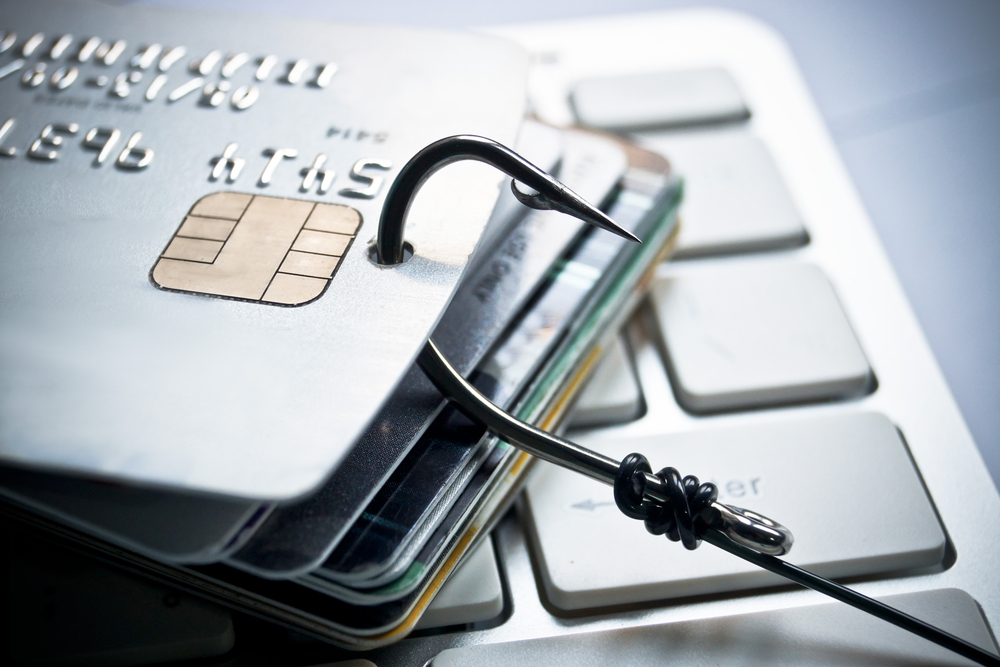

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Objective</b></p>
<p>Card issuers receive large volumes of applications, and a small share of them is unusual in ways that justify a manual review: attribute combinations that rarely occur together, extreme values, or profiles that fit none of the usual applicant groups. This project builds a <b>screening system that ranks applications by how atypical they are</b>, with a <b>Self-Organizing Map (SOM)</b> as the central model.</p>
<p style="margin-bottom:0">The data contains no fraud labels, so the task is framed as <b>unsupervised anomaly detection</b>, and every result is stated in terms of <i>potentially</i> fraudulent applications. <b>Section A</b> screens applications without labels and compares the SOM with an Autoencoder, a Variational Autoencoder and Deep SVDD. <b>Section B</b> uses the recorded application outcome as target to measure how much unsupervised structure helps a classifier when only a fraction of the labels is available.</p>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Dataset</b></p>
<p>This dataset contains <b>690</b> anonymised credit card applications described by <b>14 attributes</b> (<code>A1</code> to <code>A14</code>): <b>6 numeric</b> (<code>A2</code>, <code>A3</code>, <code>A7</code>, <code>A10</code>, <code>A13</code>, <code>A14</code>), <b>4 binary</b> (<code>A1</code>, <code>A8</code>, <code>A9</code>, <code>A11</code>) and <b>4 categorical</b> with 3 to 14 levels (<code>A4</code>, <code>A5</code>, <code>A6</code>, <code>A12</code>). There are no missing values. A binary attribute, <b><code>Class</code></b>, records the outcome of each application (44.5% positive).</p>
<p>All attribute names and values were replaced by meaningless symbols to protect confidentiality, so the attributes can only be interpreted statistically. <code>CustomerID</code> is an identifier and is not used by any model. <code>Class</code> is a credit decision, not a fraud label: it is never used for training in Section A and serves as the prediction target in Section B.</p>
<p style="margin-bottom:0"><b>Source:</b> Kaggle dataset <a href="https://www.kaggle.com/datasets/mbsoroush/credit-cards-applications" style="color:#c27849; font-weight:600">mbsoroush/credit-cards-applications</a>. The data follows the structure of the Statlog (Australian Credit Approval) dataset: R. Quinlan (1987), <i>Statlog (Australian Credit Approval)</i>, UCI Machine Learning Repository, <a href="https://doi.org/10.24432/C59012" style="color:#c27849; font-weight:600">doi:10.24432/C59012</a> (CC BY 4.0).</p>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Contents</b></p>
<ul style="margin-bottom:0">
<li><a href="#sec0" style="color:#c27849; font-weight:600">0 · Methodology</a>
</li>
<li><a href="#secA" style="color:#c27849; font-weight:600">Section A · Unsupervised fraud screening</a>
<ul>
<li><a href="#secA1" style="color:#c27849; font-weight:600">A1 · Setup and configuration</a></li>
<li><a href="#secA2" style="color:#c27849; font-weight:600">A2 · Data</a></li>
<li><a href="#secA3" style="color:#c27849; font-weight:600">A3 · Exploratory analysis</a></li>
<li><a href="#secA4" style="color:#c27849; font-weight:600">A4 · Preprocessing</a></li>
<li><a href="#secA5" style="color:#c27849; font-weight:600">A5 · Self-Organizing Map</a></li>
<li><a href="#secA6" style="color:#c27849; font-weight:600">A6 · SOM hyperparameter selection</a></li>
<li><a href="#secA7" style="color:#c27849; font-weight:600">A7 · Final SOM and map analysis</a></li>
<li><a href="#secA8" style="color:#c27849; font-weight:600">A8 · Anomaly scoring and flagged applications</a></li>
<li><a href="#secA9" style="color:#c27849; font-weight:600">A9 · Map regions and application outcome</a></li>
<li><a href="#secA10" style="color:#c27849; font-weight:600">A10 · Neural network detectors</a></li>
<li><a href="#secA11" style="color:#c27849; font-weight:600">A11 · Benchmark with injected anomalies</a></li>
<li><a href="#secA12" style="color:#c27849; font-weight:600">A12 · Stability and agreement</a></li>
<li><a href="#secA13" style="color:#c27849; font-weight:600">A13 · Comparison with the application outcome</a></li>
<li><a href="#secA14" style="color:#c27849; font-weight:600">A14 · Summary of Section A and saved artifacts</a></li>
</ul></li>
<li><a href="#secB" style="color:#c27849; font-weight:600">Section B · Semi-supervised learning with scarce labels</a>
<ul>
<li><a href="#secB1" style="color:#c27849; font-weight:600">B1 · Protocol</a></li>
<li><a href="#secB2" style="color:#c27849; font-weight:600">B2 · Models</a></li>
<li><a href="#secB3" style="color:#c27849; font-weight:600">B3 · Classifiers</a></li>
<li><a href="#secB4" style="color:#c27849; font-weight:600">B4 · Experiment</a></li>
<li><a href="#secB5" style="color:#c27849; font-weight:600">B5 · Results by label fraction</a></li>
<li><a href="#secB6" style="color:#c27849; font-weight:600">B6 · Effect of unsupervised structure</a></li>
<li><a href="#secB7" style="color:#c27849; font-weight:600">B7 · Summary of Section B and saved artifacts</a></li>
</ul></li>
<li><a href="#secConclusions" style="color:#c27849; font-weight:600">Conclusions</a>
</li>
</ul>
</div>

<a class="anchor" id="sec0"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:170%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">0 · Methodology</p>

* **Framing:** unsupervised anomaly detection. No fraud labels exist, so claims are limited to *potentially* fraudulent applications. `CustomerID` is excluded from every model, and `Class` is excluded from all Section A models.
* **Pre-processing:** skewed numeric attributes (absolute skewness above 1) are log-transformed and all numeric attributes are standardised. Categorical attributes are one-hot encoded, and binary attributes are scaled by $\sqrt{2}$, so that every attribute type contributes a comparable squared distance (2 for a mismatch). In every cross-validation, the encoder is refitted on the training folds only.
* **SOM:** NumPy implementation from scratch (online training, Gaussian neighbourhood, asymptotic decay), validated against MiniSom. The grid side follows the $5\sqrt{N}$ rule of thumb (11 × 11), and radius and learning rate are selected by held-out quantization and topographic error. The anomaly score of an application is its distance to the best-matching neuron.
* **Evaluation without fraud labels:** four complementary pieces of evidence: a benchmark with synthetic anomalies injected into held-out applications, stability across random seeds, agreement between detectors, and a descriptive comparison with the application outcome.
* **Benchmark protocol (Section A):** 5-fold cross-validation repeated three times. Every detector and the preprocessing are fitted on the training folds only, and two anomaly types (inconsistent profiles and extreme values) are injected into each held-out fold. Metrics are the ROC-AUC and the average precision at a 10% anomaly share. The architectures of the neural detectors are fixed in advance and are not tuned on the benchmark.
* **Semi-supervised protocol (Section B):** stratified 5-fold cross-validation repeated twice. Label fractions of 5%, 10%, 25%, 50% and 100% are nested, stratified subsets of each training fold. The unsupervised stages (SOM, autoencoder, TabNet pretraining) see all training rows of the fold without labels. Hyperparameters and training budgets are fixed, and the test fold is never used before the final prediction. Metrics are the ROC-AUC and the accuracy.
* **Reproducibility:** all random seeds are fixed. Trained models and result tables are saved to an `artifacts` folder together with a manifest (data hash and configuration), and a later run loads every matching artifact instead of training again.
* **Hardware:** the neural models are small and train on a single GPU (or on the CPU). The SOM runs on the CPU.

<a class="anchor" id="secA"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:170%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Section A · Unsupervised fraud screening</p>

Section A treats the applications as unlabeled. It implements and validates the SOM, selects its settings with held-out error, scores and explains every application, and compares the SOM with three neural detectors on a controlled benchmark, on stability across seeds and on agreement between detectors.

<a class="anchor" id="secA1"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A1 · Setup and configuration</p>


All settings live in one configuration dictionary. Trained models and result tables are written to an `artifacts` folder together with a manifest that records the data hash and the configuration. A later run reuses every artifact whose manifest matches, so no model is trained twice.

In [1]:
import hashlib
import json
import random
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import skew
from sklearn.cluster import KMeans
from sklearn.metrics import average_precision_score, roc_auc_score, silhouette_score
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

QUICK_RUN = False       # True runs a reduced configuration to check the pipeline quickly
FORCE_RETRAIN = False   # True ignores saved artifacts and trains everything again

SEED = 42

CONFIG = {
    "seed": SEED,
    "skew_threshold": 1.0,
    "som": {
        "grid_sides": [6, 8, 10, 14, 18],
        "sigmas": [1.0, 2.0, 3.0],
        "learning_rates": [0.1, 0.5],
        "max_topographic_error": 0.20,
        "search_epochs": 50,
        "final_epochs": 100,
        "cv_folds": 5,
        "sensitivity_sides": [6, 8, 11, 14, 18, 24],
    },
    "neural": {
        "hidden": 64,
        "latent": 8,
        "epochs": 200,
        "batch_size": 64,
        "lr": 1e-3,
        "weight_decay": 1e-5,
        "vae_beta": 1.0,
        "svdd_pretrain_epochs": 100,
        "svdd_epochs": 100,
        "svdd_lr": 5e-4,
    },
    "benchmark": {
        "n_splits": 5,
        "n_repeats": 3,
        "mixed_features": 4,
        "extreme_features": 2,
        "extreme_factor": [1.5, 3.0],
        "contamination": 0.10,
    },
    "stability_seeds": 10,
    "flag_rate": 0.05,
    "semi": {
        "label_fractions": [0.05, 0.10, 0.25, 0.50, 1.00],
        "n_splits": 5,
        "n_repeats": 2,
        "som_vote_smoothing": 1.0,
        "mlp": {"hidden": 64, "dropout": 0.2, "steps": 400, "batch_size": 32, "lr": 1e-3, "weight_decay": 1e-4},
        "ftt": {"d_token": 16, "n_blocks": 2, "n_heads": 2, "dropout": 0.1, "steps": 400, "batch_size": 32,
                "lr": 1e-3, "weight_decay": 1e-4},
        "tabnet": {"n_d": 8, "n_a": 8, "n_steps": 3, "gamma": 1.3, "lr": 0.02, "epochs": 100,
                   "pretrain_epochs": 60, "pretraining_ratio": 0.5, "batch_size": 64, "virtual_batch_size": 32},
    },
}

if QUICK_RUN:
    CONFIG["som"].update(grid_sides=[6, 10], sigmas=[1.0, 2.0], learning_rates=[0.5],
                         search_epochs=10, final_epochs=20, cv_folds=3, sensitivity_sides=[6, 11])
    CONFIG["neural"].update(epochs=20, svdd_pretrain_epochs=10, svdd_epochs=10)
    CONFIG["benchmark"].update(n_splits=3, n_repeats=1)
    CONFIG["stability_seeds"] = 3
    CONFIG["semi"].update(label_fractions=[0.1, 0.5, 1.0], n_splits=3, n_repeats=1, som_vote_smoothing=1.0)
    for key in ("mlp", "ftt"):
        CONFIG["semi"][key]["steps"] = 30
    CONFIG["semi"]["tabnet"].update(epochs=3, pretrain_epochs=3)

FLAG_RATE = CONFIG["flag_rate"]

In [2]:
ON_KAGGLE = Path("/kaggle/input").exists()
WORK_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("working")
ARTIFACT_DIR = WORK_DIR / "artifacts"
FIG_DIR = ARTIFACT_DIR / "figures"


def locate(filename, roots=("/kaggle/input", ".")):
    """Return the first file with the given name found below the search roots."""
    for root in roots:
        if Path(root).exists():
            for hit in Path(root).rglob(filename):
                return hit
    raise FileNotFoundError(f"{filename} was not found among the notebook inputs.")


class ArtifactStore:
    """Persists trained models and result tables so that each one is computed only once."""

    def __init__(self, out_dir, data_sha, signature, force=False):
        self.out_dir, self.force = Path(out_dir), force
        self.manifest = {"data_sha256": data_sha, "config_signature": signature}
        self.out_dir.mkdir(parents=True, exist_ok=True)
        if self._read_manifest(self.out_dir) != self.manifest:
            for item in self.out_dir.iterdir():
                if item.is_file():
                    item.unlink()
            (self.out_dir / "manifest.json").write_text(json.dumps(self.manifest, indent=2))
        self.prior_dirs = [] if force else self._find_priors()

    @staticmethod
    def _read_manifest(directory):
        path = Path(directory) / "manifest.json"
        return json.loads(path.read_text()) if path.exists() else None

    def _find_priors(self):
        root = Path("/kaggle/input")
        found = []
        if root.exists():
            for manifest in sorted(root.rglob("manifest.json")):
                if self._read_manifest(manifest.parent) == self.manifest:
                    found.append(manifest.parent)
        return found

    def path(self, name):
        return self.out_dir / name

    def lookup(self, name):
        """Return a local path to a valid saved artifact, or None if it has to be computed."""
        if self.force:
            return None
        local = self.out_dir / name
        if local.exists():
            return local
        for directory in self.prior_dirs:
            if (directory / name).exists():
                shutil.copy2(directory / name, local)
                return local
        return None


DATA_PATH = locate("Credit_Card_Applications.csv")
DATA_SHA = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
# Section B settings are excluded so that saved Section A artifacts stay valid when only Section B changes.
SIGNATURE = hashlib.sha256(json.dumps({k: v for k, v in CONFIG.items() if k != "semi"},
                                       sort_keys=True).encode()).hexdigest()

store = ArtifactStore(ARTIFACT_DIR, DATA_SHA, SIGNATURE, force=FORCE_RETRAIN)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data file      : {DATA_PATH}")
print(f"Artifact folder: {ARTIFACT_DIR}")
print("Saved artifacts:", "reusing " + ", ".join(map(str, store.prior_dirs)) if store.prior_dirs
      else "none found, models will be trained")


def cached_table(name, builder):
    """Load a result table from the artifact store, or build it and save it."""
    path = store.lookup(name)
    if path is not None:
        print(f"Loaded saved result: {name}")
        return pd.read_csv(path)
    table = builder()
    table.to_csv(store.path(name), index=False)
    return table


METRIC_LABELS = {"roc_auc": "ROC-AUC", "average_precision": "average precision", "accuracy": "accuracy"}


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name)

Data file      : /kaggle/input/credit-cards-applications/Credit_Card_Applications.csv
Artifact folder: /kaggle/working/artifacts
Saved artifacts: reusing /kaggle/input/notebooks/mbsoroush/fraud-screening-self-organizing-maps/artifacts


<a class="anchor" id="secA2"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A2 · Data</p>


The attributes are anonymised. Six are numeric (`A2`, `A3`, `A7`, `A10`, `A13`, `A14`), four are binary (`A1`, `A8`, `A9`, `A11`) and four are categorical with 3 to 14 levels (`A4`, `A5`, `A6`, `A12`). `CustomerID` is an identifier and is excluded from every model. `Class` is excluded from all Section A models.

In [3]:
df = pd.read_csv(DATA_PATH)

ID_COL, TARGET = "CustomerID", "Class"
NUMERIC = ["A2", "A3", "A7", "A10", "A13", "A14"]
BINARY = ["A1", "A8", "A9", "A11"]
CATEGORICAL = ["A4", "A5", "A6", "A12"]
FEATURES = NUMERIC + BINARY + CATEGORICAL
assert set(FEATURES) | {ID_COL, TARGET} == set(df.columns)

integrity = pd.Series({
    "applications": len(df),
    "attributes": len(FEATURES),
    "missing values": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "unique customer ids": int(df[ID_COL].nunique()),
    "share with outcome = 1": round(float(df[TARGET].mean()), 3),
}, name="value", dtype=object).to_frame()
display(integrity)

schema = pd.DataFrame({
    "type": ["numeric"] * len(NUMERIC) + ["binary"] * len(BINARY) + ["categorical"] * len(CATEGORICAL),
    "distinct values": [df[c].nunique() for c in FEATURES],
    "min": [df[c].min() for c in FEATURES],
    "max": [df[c].max() for c in FEATURES],
    "skewness": [round(float(skew(df[c].to_numpy(float))), 2) for c in FEATURES],
}, index=FEATURES)
display(schema)

,value
applications,690
attributes,14
missing values,0
duplicate rows,0
unique customer ids,690
share with outcome = 1,0.445


,type,distinct values,min,max,skewness
A2,numeric,350,13.75,80.25,1.15
A3,numeric,215,0.00,28.00,1.49
A7,numeric,132,0.00,28.50,2.89
A10,numeric,23,0.00,67.00,5.14
A13,numeric,171,0.00,2000.00,2.74
A14,numeric,240,1.00,100001.00,13.11
A1,binary,2,0.00,1.00,-0.76
A8,binary,2,0.00,1.00,-0.09
A9,binary,2,0.00,1.00,0.29
A11,binary,2,0.00,1.00,0.17


<a class="anchor" id="secA3"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A3 · Exploratory analysis</p>


Three questions matter for a distance-based model such as the SOM: how skewed are the numeric attributes, how are the discrete attributes distributed, and how strongly are attributes related to each other.

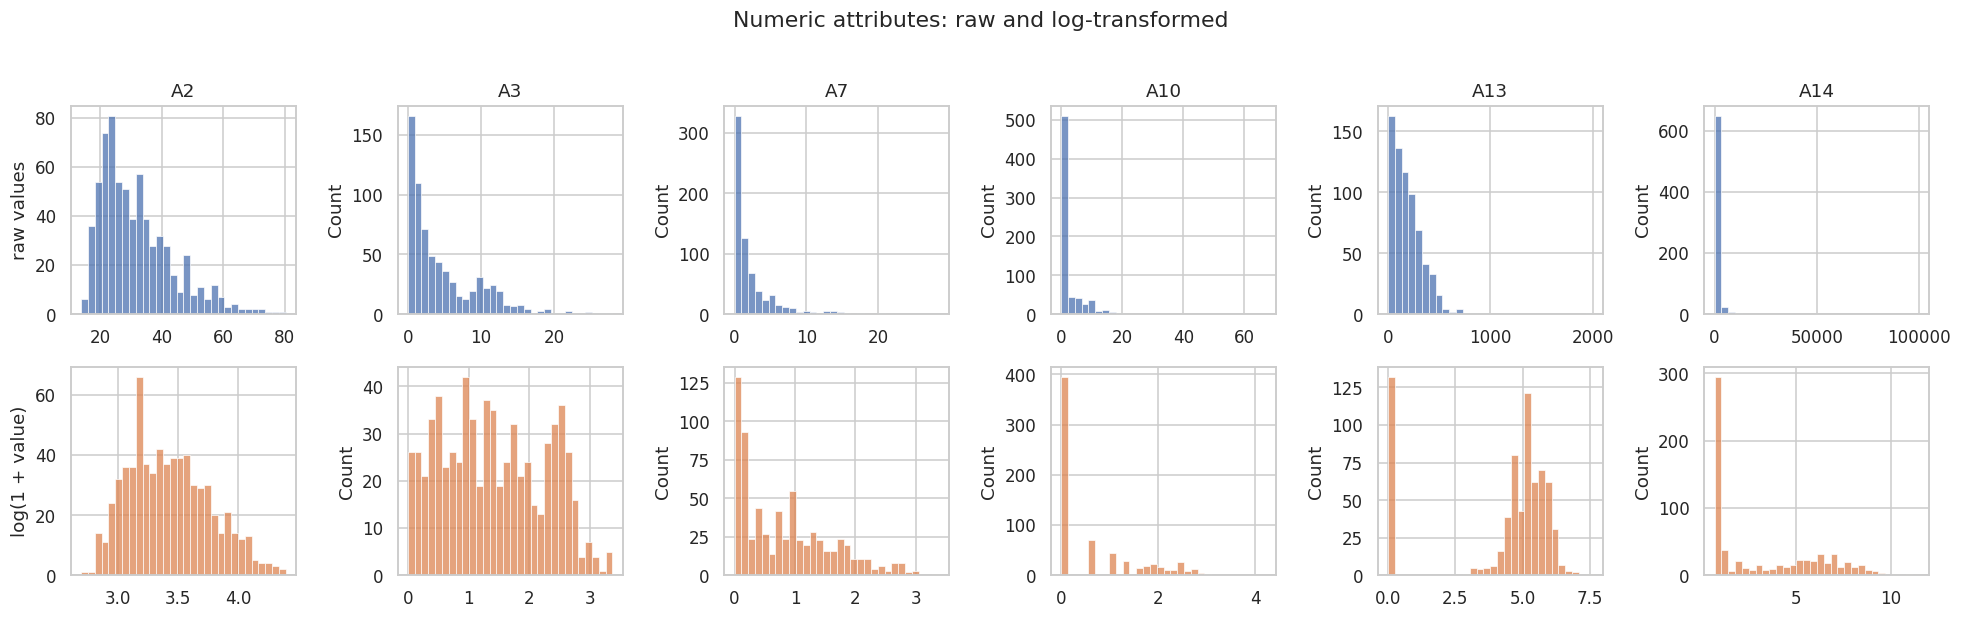

In [4]:
fig, axes = plt.subplots(2, len(NUMERIC), figsize=(18, 5.5))
for i, col in enumerate(NUMERIC):
    sns.histplot(df[col], bins=30, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")
    sns.histplot(np.log1p(df[col]), bins=30, ax=axes[1, i], color="#DD8452")
    axes[1, i].set_xlabel("")
axes[0, 0].set_ylabel("raw values")
axes[1, 0].set_ylabel("log(1 + value)")
fig.suptitle("Numeric attributes: raw and log-transformed", y=1.02)
fig.tight_layout()
save_fig(fig, "01_numeric_distributions.png")
plt.show()

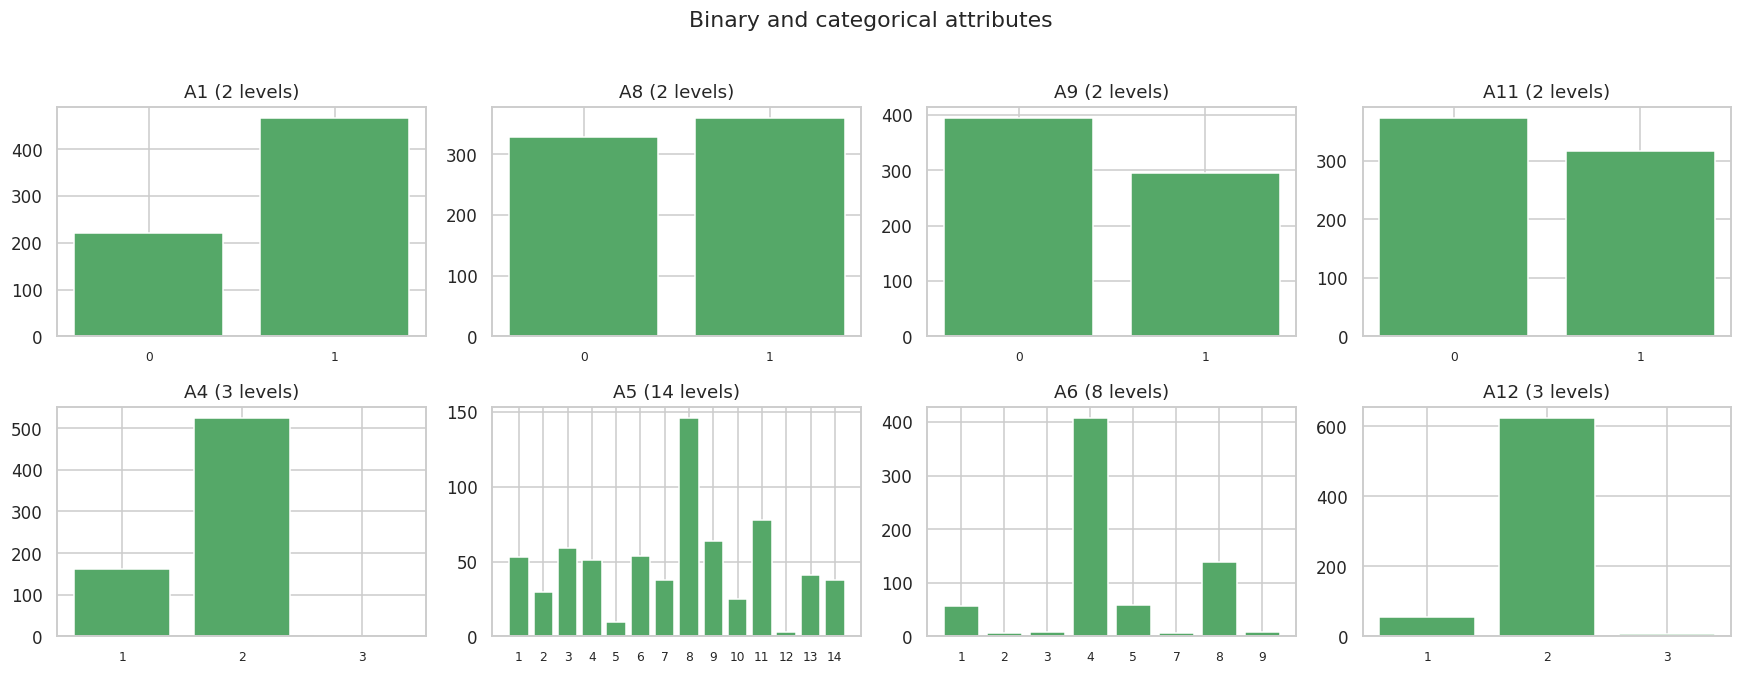

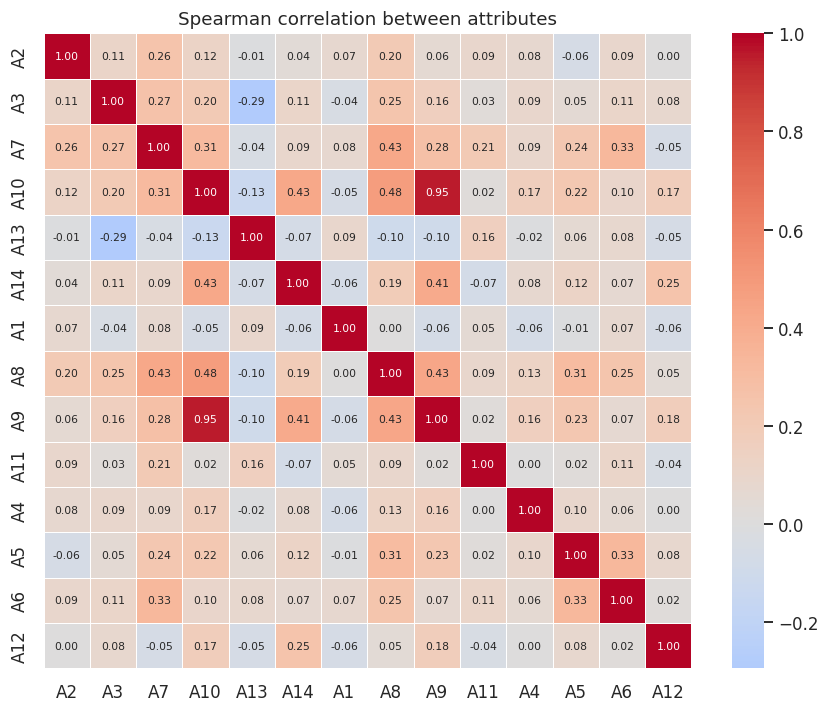

In [5]:
discrete = BINARY + CATEGORICAL
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), discrete):
    counts = df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color="#55A868")
    ax.set_title(f"{col} ({df[col].nunique()} levels)")
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Binary and categorical attributes", y=1.02)
fig.tight_layout()
save_fig(fig, "02_discrete_distributions.png")
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(df[FEATURES].corr(method="spearman"), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, ax=ax)
ax.set_title("Spearman correlation between attributes")
save_fig(fig, "03_attribute_correlation.png")
plt.show()

**Observations.** The numeric attributes are strongly right-skewed (skewness of 13.1 for `A14`, 5.1 for `A10`, 2.9 for `A7`), which the log transform reduces. The attributes are only weakly related to each other: 89% of the 91 attribute pairs have an absolute Spearman correlation below 0.3, and the median is 0.09. Two relationships stand out. `A10` is zero exactly when `A9` is 0 (correlation 0.95), and several pairs among `A7`, `A8`, `A9`, `A10` and `A14` correlate between 0.41 and 0.48. `A8` also separates the application outcome strongly: 79% of the applications with `A8 = 1` have outcome 1, against 7% of those with `A8 = 0`.

Weak dependence between attributes matters for anomaly detection. An unusual *combination* of attributes can only be detected where attributes constrain each other, whereas unusually *large* values are detectable in any case.

<a class="anchor" id="secA4"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A4 · Preprocessing</p>


The SOM compares applications through Euclidean distance, so every attribute type has to contribute on a comparable scale.

- **Skewed numeric attributes** (absolute skewness above the configured threshold) are transformed with $\log(1+x)$ so that a few very large values do not dominate the distance. The transform is selected from the training data only.
- **Numeric attributes** are standardised to zero mean and unit variance.
- **Categorical attributes** are one-hot encoded. Two different categories differ in two coordinates, which gives a squared distance of 2, the same as the expected squared difference between two random standardised numeric values.
- **Binary attributes** are scaled by $\sqrt{2}$ so that a mismatch also contributes a squared distance of 2.

The encoder is a fitted object: in the benchmark it is refitted inside every training fold, so that no statistic of a held-out application leaks into a model.

In [6]:
class Preprocessor:
    """Log transform, standardisation and one-hot encoding with a distance-consistent scale."""

    def __init__(self, numeric, binary, categorical, skew_threshold=1.0):
        self.numeric, self.binary, self.categorical = list(numeric), list(binary), list(categorical)
        self.skew_threshold = skew_threshold
        self.binary_scale = float(np.sqrt(2.0))

    def _numeric_block(self, frame):
        columns = []
        for col in self.numeric:
            values = frame[col].to_numpy(float)
            columns.append(np.log1p(values) if col in self.log_cols_ else values)
        return np.column_stack(columns)

    def fit(self, frame):
        self.log_cols_ = [c for c in self.numeric if abs(skew(frame[c].to_numpy(float))) > self.skew_threshold]
        block = self._numeric_block(frame)
        self.mean_ = block.mean(axis=0)
        std = block.std(axis=0)
        self.std_ = np.where(std > 0, std, 1.0)
        self.levels_ = {c: sorted(frame[c].unique().tolist()) for c in self.categorical}

        names, blocks, position = [], {}, 0
        for col in self.numeric:
            names.append(f"log({col})" if col in self.log_cols_ else col)
            blocks[col] = [position]
            position += 1
        for col in self.binary:
            names.append(col)
            blocks[col] = [position]
            position += 1
        for col in self.categorical:
            blocks[col] = list(range(position, position + len(self.levels_[col])))
            names += [f"{col}={level}" for level in self.levels_[col]]
            position += len(self.levels_[col])
        self.feature_names_, self.blocks_ = names, blocks
        return self

    def transform(self, frame):
        parts = [(self._numeric_block(frame) - self.mean_) / self.std_,
                 frame[self.binary].to_numpy(float) * self.binary_scale]
        for col in self.categorical:
            values = frame[col].to_numpy()
            parts.append(np.column_stack([(values == level).astype(float) for level in self.levels_[col]]))
        return np.hstack(parts)

    def to_dict(self):
        return {"log_columns": self.log_cols_, "mean": self.mean_.tolist(), "std": self.std_.tolist(),
                "levels": {k: [float(v) for v in vals] for k, vals in self.levels_.items()},
                "binary_scale": self.binary_scale, "feature_names": self.feature_names_}


pre = Preprocessor(NUMERIC, BINARY, CATEGORICAL, CONFIG["skew_threshold"]).fit(df[FEATURES])
X_all = pre.transform(df[FEATURES])
store.path("preprocessing.json").write_text(json.dumps(pre.to_dict(), indent=2))

print(f"Model input: {X_all.shape[0]} applications x {X_all.shape[1]} dimensions")
print(f"Log-transformed attributes: {pre.log_cols_}")

Model input: 690 applications x 38 dimensions
Log-transformed attributes: ['A2', 'A3', 'A7', 'A10', 'A13', 'A14']


<a class="anchor" id="secA5"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A5 · Self-Organizing Map</p>


A SOM is a grid of neurons, each holding a weight vector in the input space. Training pulls the weights towards the data while keeping neighbouring neurons close to each other, so the grid becomes a two-dimensional map of the application space.

For every sample $x$ the **best-matching unit** is $c(x)=\arg\min_i \lVert x-w_i\rVert$, and all neurons are updated as

$$w_i \leftarrow w_i + \alpha(t)\,h_{ci}(t)\,(x-w_i), \qquad h_{ci}(t)=\exp\!\left(-\frac{d_{ci}^2}{2\sigma(t)^2}\right),$$

where $d_{ci}$ is the grid distance between neuron $i$ and the winner. Learning rate and neighbourhood radius decay as $\alpha(t)=\alpha_0/(1+2t/T)$ and $\sigma(t)=\sigma_0/(1+2t/T)$ over $T$ iterations.

The **anomaly score** of an application is its *quantization distance* $\lVert x-w_{c(x)}\rVert$: the distance to the closest neuron. An application far from every prototype of normal behaviour is unusual. Map quality is measured with two standard errors:

- **Quantization error (QE):** mean quantization distance. It measures how well the prototypes represent the data.
- **Topographic error (TE):** share of samples whose two closest neurons are not adjacent on the grid. It measures how well the map preserves the neighbourhood structure.

The implementation below uses NumPy only.

In [7]:
class SelfOrganizingMap:
    """Online Self-Organizing Map on a rectangular grid with a Gaussian neighbourhood."""

    def __init__(self, rows, cols, input_dim, sigma=1.5, learning_rate=0.5, seed=0):
        self.rows, self.cols, self.input_dim = int(rows), int(cols), int(input_dim)
        self.sigma, self.learning_rate, self.seed = float(sigma), float(learning_rate), int(seed)
        grid_row, grid_col = np.divmod(np.arange(self.rows * self.cols), self.cols)
        self.grid = np.stack([grid_row, grid_col], axis=1).astype(float)
        self.weights = None

    def fit(self, X, epochs=100):
        X = np.asarray(X, dtype=float)
        n = len(X)
        rng = np.random.default_rng(self.seed)
        weights = X[rng.integers(0, n, self.rows * self.cols)].copy()
        order = np.concatenate([rng.permutation(n) for _ in range(int(epochs))])
        total = len(order)
        for t, i in enumerate(order):
            decay = 1.0 + 2.0 * t / total
            x = X[i]
            winner = np.argmin(((weights - x) ** 2).sum(axis=1))
            grid_dist2 = ((self.grid - self.grid[winner]) ** 2).sum(axis=1)
            influence = np.exp(-grid_dist2 / (2.0 * (self.sigma / decay) ** 2))
            weights += ((self.learning_rate / decay) * influence)[:, None] * (x - weights)
        self.weights = weights
        return self

    def _distances(self, X):
        X = np.asarray(X, dtype=float)
        squared = (X ** 2).sum(1)[:, None] - 2.0 * X @ self.weights.T + (self.weights ** 2).sum(1)[None, :]
        return np.sqrt(np.maximum(squared, 0.0))

    def winners(self, X):
        distances = self._distances(X)
        winner = distances.argmin(axis=1)
        return winner, distances[np.arange(len(distances)), winner]

    def score(self, X):
        return self.winners(X)[1]

    def quantization_error(self, X):
        return float(self.score(X).mean())

    def topographic_error(self, X):
        two_best = np.argpartition(self._distances(X), 1, axis=1)[:, :2]
        gap = np.linalg.norm(self.grid[two_best[:, 0]] - self.grid[two_best[:, 1]], axis=1)
        return float((gap > 1.5).mean())

    def u_matrix(self):
        W = self.weights.reshape(self.rows, self.cols, -1)
        U = np.zeros((self.rows, self.cols))
        for r in range(self.rows):
            for c in range(self.cols):
                neighbours = [W[rr, cc]
                              for rr in range(max(r - 1, 0), min(r + 2, self.rows))
                              for cc in range(max(c - 1, 0), min(c + 2, self.cols))
                              if (rr, cc) != (r, c)]
                U[r, c] = np.mean([np.linalg.norm(W[r, c] - v) for v in neighbours])
        return U

    def hit_map(self, X):
        winner, _ = self.winners(X)
        return np.bincount(winner, minlength=self.rows * self.cols).reshape(self.rows, self.cols)

    def neuron_average(self, X, values):
        """Average of a per-sample quantity over the samples mapped to each neuron (NaN if none)."""
        winner, _ = self.winners(X)
        size = self.rows * self.cols
        sums = np.bincount(winner, weights=np.asarray(values, float), minlength=size)
        counts = np.bincount(winner, minlength=size)
        out = np.full(size, np.nan)
        np.divide(sums, counts, out=out, where=counts > 0)
        return out.reshape(self.rows, self.cols)

    def save(self, path):
        np.savez(path, weights=self.weights, rows=self.rows, cols=self.cols, input_dim=self.input_dim,
                 sigma=self.sigma, learning_rate=self.learning_rate, seed=self.seed)

    @classmethod
    def load(cls, path):
        z = np.load(path)
        som = cls(int(z["rows"]), int(z["cols"]), int(z["input_dim"]), float(z["sigma"]),
                  float(z["learning_rate"]), int(z["seed"]))
        som.weights = z["weights"]
        return som


class SOMDetector:
    """Detector interface (fit / score) around the SOM, shared with the neural detectors."""
    name = "SOM"

    def __init__(self, input_dim, seed=0, side=10, sigma=2.0, learning_rate=0.5, epochs=100):
        self.input_dim, self.seed = input_dim, seed
        self.params = dict(side=side, sigma=sigma, learning_rate=learning_rate, epochs=epochs)

    def fit(self, X):
        p = self.params
        self.model = SelfOrganizingMap(p["side"], p["side"], self.input_dim, p["sigma"],
                                       p["learning_rate"], self.seed).fit(X, p["epochs"])
        return self

    def score(self, X):
        return self.model.score(X)

### Validation against MiniSom

[MiniSom](https://github.com/JustGlowing/minisom) is a widely used SOM library. Both implementations are trained with identical settings (grid, radius, learning rate, number of iterations, random initialisation from samples, Gaussian neighbourhood, asymptotic decay) over five seeds. Because the initialisation and sample order differ, the maps are not identical, so the comparison is statistical:

- QE and TE are computed with the same functions on both sets of weights.
- The rank correlation of anomaly scores between the two implementations is compared with the rank correlation between different seeds of the same implementation. Agreement across implementations should be as high as agreement across seeds.

In [8]:
def import_minisom():
    try:
        from minisom import MiniSom
        return MiniSom
    except ImportError:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "minisom"],
                           capture_output=True, timeout=180)
            from minisom import MiniSom
            return MiniSom
        except Exception:
            return None


def rank_correlation(a, b):
    return pd.Series(a).corr(pd.Series(b), method="spearman")


def mean_pairwise(first, second, same_set):
    values = [rank_correlation(a, b)
              for i, a in enumerate(first) for j, b in enumerate(second) if (i < j if same_set else True)]
    return float(np.mean(values))


MiniSom = import_minisom()

if MiniSom is None:
    print("MiniSom is not available (internet access is disabled), the cross-check is skipped.")
else:
    CHECK = dict(side=10, sigma=2.0, learning_rate=0.5, epochs=50 if not QUICK_RUN else 10, seeds=5 if not QUICK_RUN else 3)
    own_runs, mini_runs = [], []
    for seed in range(CHECK["seeds"]):
        own = SelfOrganizingMap(CHECK["side"], CHECK["side"], X_all.shape[1], CHECK["sigma"],
                                CHECK["learning_rate"], seed).fit(X_all, CHECK["epochs"])
        mini = MiniSom(CHECK["side"], CHECK["side"], X_all.shape[1], sigma=CHECK["sigma"],
                       learning_rate=CHECK["learning_rate"], neighborhood_function="gaussian",
                       random_seed=seed)
        mini.random_weights_init(X_all)
        mini.train(X_all, CHECK["epochs"] * len(X_all), random_order=True)
        wrapped = SelfOrganizingMap(CHECK["side"], CHECK["side"], X_all.shape[1])
        wrapped.weights = mini.get_weights().reshape(CHECK["side"] ** 2, -1).copy()
        own_runs.append(own)
        mini_runs.append(wrapped)

    summary = pd.DataFrame({
        "implementation": ["This notebook (NumPy)", "MiniSom"],
        "quantization error": [np.mean([m.quantization_error(X_all) for m in runs]) for runs in (own_runs, mini_runs)],
        "quantization error (std)": [np.std([m.quantization_error(X_all) for m in runs]) for runs in (own_runs, mini_runs)],
        "topographic error": [np.mean([m.topographic_error(X_all) for m in runs]) for runs in (own_runs, mini_runs)],
        "topographic error (std)": [np.std([m.topographic_error(X_all) for m in runs]) for runs in (own_runs, mini_runs)],
    }).round(4)
    display(summary)

    own_scores = [m.score(X_all) for m in own_runs]
    mini_scores = [m.score(X_all) for m in mini_runs]
    agreement = pd.Series({
        "NumPy vs NumPy (different seeds)": mean_pairwise(own_scores, own_scores, True),
        "MiniSom vs MiniSom (different seeds)": mean_pairwise(mini_scores, mini_scores, True),
        "NumPy vs MiniSom": mean_pairwise(own_scores, mini_scores, False),
    }, name="mean Spearman correlation of anomaly scores").round(3)
    display(agreement.to_frame())

,implementation,quantization error,quantization error (std),topographic error,topographic error (std)
0,This notebook (NumPy),1.9069,0.0036,0.0809,0.0056
1,MiniSom,1.9360,0.0037,0.1061,0.0168


,mean Spearman correlation of anomaly scores
NumPy vs NumPy (different seeds),0.790
MiniSom vs MiniSom (different seeds),0.691
NumPy vs MiniSom,0.745


**Result.** Both implementations reach a similar map quality: quantization error 1.907 (NumPy) against 1.936 (MiniSom), and topographic error 0.081 against 0.106. The rank correlation of the anomaly scores between the two implementations (0.745) lies between the values obtained across seeds within each implementation (0.790 for NumPy, 0.691 for MiniSom). Differences between the two implementations are therefore no larger than differences between random seeds of the same implementation. The seed-to-seed correlations also show that the ranking of individual applications depends noticeably on the random initialisation, which A12 quantifies.

<a class="anchor" id="secA6"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A6 · SOM hyperparameter selection</p>


**Grid size.** Held-out quantization error keeps falling as the grid grows, because more prototypes always fit better (the same holds for k-means), so this error alone cannot choose the size. For anomaly detection a very large map is also counterproductive: an outlying application can claim a neuron of its own and then looks perfectly typical. The grid side therefore follows the common rule of thumb of about $5\sqrt{N}$ neurons, which gives an 11 x 11 map for 690 applications. The search below still covers a wide range of sizes as a diagnostic, and A11 reports how the benchmark result depends on the grid size.

**Radius and learning rate.** For the chosen grid size, the neighbourhood radius and learning rate are selected with 5-fold cross-validation: the setting with the lowest held-out quantization error is selected among all settings whose held-out topographic error does not exceed the configured limit. Radii larger than half the grid side are excluded, and labels play no role.

The scaling statistics are computed on all rows here, because the search only compares SOM settings with each other. The benchmark in A11 refits the preprocessing inside every training fold.

In [9]:
def som_search(X, cfg, sides, seed):
    splitter = KFold(cfg["cv_folds"], shuffle=True, random_state=seed)
    rows = []
    for side in sides:
        for sigma in cfg["sigmas"]:
            if sigma > side / 2:
                continue
            for learning_rate in cfg["learning_rates"]:
                train_qe, val_qe, val_te = [], [], []
                for fold, (tr, va) in enumerate(splitter.split(X)):
                    som = SelfOrganizingMap(side, side, X.shape[1], sigma, learning_rate, seed + fold)
                    som.fit(X[tr], cfg["search_epochs"])
                    train_qe.append(som.quantization_error(X[tr]))
                    val_qe.append(som.quantization_error(X[va]))
                    val_te.append(som.topographic_error(X[va]))
                rows.append({"grid_side": side, "sigma": sigma, "learning_rate": learning_rate,
                             "train_qe": np.mean(train_qe), "val_qe": np.mean(val_qe),
                             "val_te": np.mean(val_te)})
    return pd.DataFrame(rows)


HEURISTIC_SIDE = int(round(np.sqrt(5 * np.sqrt(len(X_all)))))
SEARCH_SIDES = sorted(set(CONFIG["som"]["grid_sides"]) | {HEURISTIC_SIDE})
print(f"Rule of thumb: about {5 * np.sqrt(len(X_all)):.0f} neurons -> {HEURISTIC_SIDE} x {HEURISTIC_SIDE} grid")

start = time.time()
search = cached_table("som_search.csv", lambda: som_search(X_all, CONFIG["som"], SEARCH_SIDES, SEED))
print(f"{len(search)} settings evaluated ({time.time() - start:.0f}s)")

candidates = search[search["grid_side"] == HEURISTIC_SIDE]
eligible = candidates[candidates["val_te"] <= CONFIG["som"]["max_topographic_error"]]
if eligible.empty:
    eligible = candidates.nsmallest(1, "val_te")
best = eligible.sort_values("val_qe").iloc[0]
BEST_SIDE, BEST_SIGMA, BEST_LR = int(best["grid_side"]), float(best["sigma"]), float(best["learning_rate"])
print(f"Selected: {BEST_SIDE}x{BEST_SIDE} grid, sigma = {BEST_SIGMA}, learning rate = {BEST_LR}")

display(candidates.sort_values("val_qe").round(4).reset_index(drop=True))

Rule of thumb: about 131 neurons -> 11 x 11 grid
Loaded saved result: som_search.csv
36 settings evaluated (0s)
Selected: 11x11 grid, sigma = 2.0, learning rate = 0.5


,grid_side,sigma,learning_rate,train_qe,val_qe,val_te
0,11,1.0,0.5,1.4839,1.9956,0.4681
1,11,1.0,0.1,1.5809,2.0050,0.4188
2,11,2.0,0.5,1.7927,2.0348,0.1536
3,11,2.0,0.1,1.8309,2.0634,0.1362
4,11,3.0,0.5,2.0168,2.1434,0.0739
5,11,3.0,0.1,2.0066,2.1506,0.0551


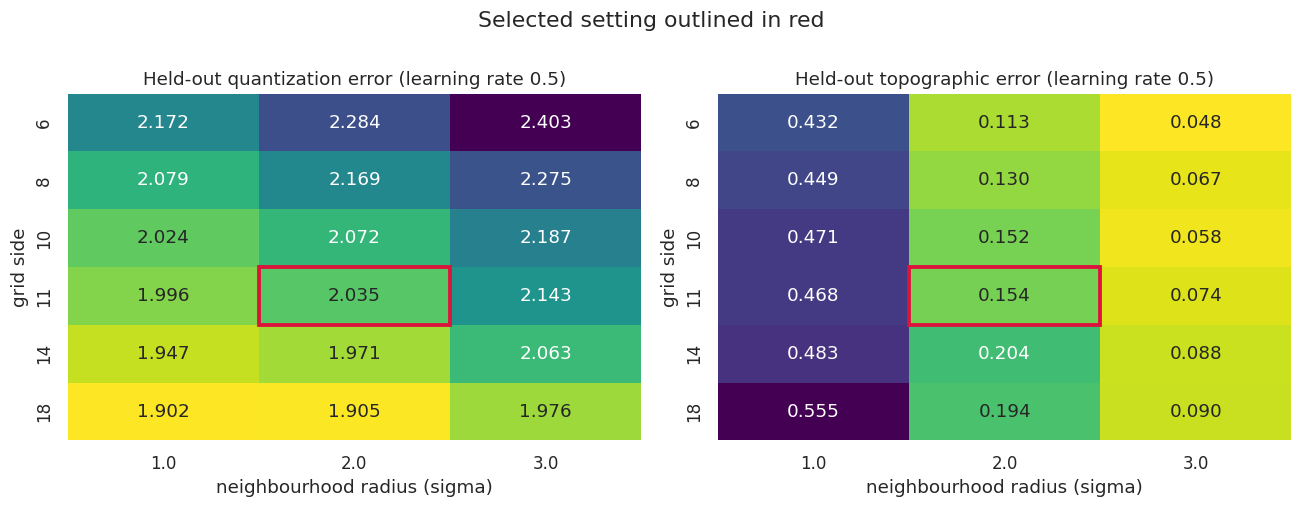

In [10]:
subset = search[search["learning_rate"] == BEST_LR]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, column, title in zip(axes, ["val_qe", "val_te"],
                             ["Held-out quantization error", "Held-out topographic error"]):
    table = subset.pivot(index="grid_side", columns="sigma", values=column)
    sns.heatmap(table, annot=True, fmt=".3f", cmap="viridis_r", ax=ax, cbar=False)
    row, col = list(table.index).index(BEST_SIDE), list(table.columns).index(BEST_SIGMA)
    ax.add_patch(plt.Rectangle((col, row), 1, 1, fill=False, edgecolor="crimson", linewidth=2.5))
    ax.set_title(f"{title} (learning rate {BEST_LR})")
    ax.set_xlabel("neighbourhood radius (sigma)")
    ax.set_ylabel("grid side")
fig.suptitle("Selected setting outlined in red", y=1.0)
fig.tight_layout()
save_fig(fig, "04_som_hyperparameter_search.png")
plt.show()

**Result.** The neighbourhood radius has the largest effect. A radius of 1 gives the lowest held-out quantization error (1.996 at learning rate 0.5) but a topographic error of 0.47, so the map folds on itself. A radius of 3 preserves the topology best (0.07) but smooths too much (quantization error 2.143). A radius of 2 keeps the topographic error within the limit (0.154) at a quantization error of 2.035. The learning rate matters little (2.035 for 0.5 against 2.063 for 0.1 at radius 2). The selected map is 11 x 11 with radius 2.0 and learning rate 0.5.

<a class="anchor" id="secA7"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A7 · Final SOM and map analysis</p>


The selected configuration is trained on all applications. Three maps describe it:

- **U-matrix:** average distance between a neuron and its neighbours. High values mark boundaries between groups of applications.
- **Hit map:** number of applications mapped to each neuron.
- **Mean quantization distance per neuron:** neurons whose applications are poorly represented by their prototype.

In [11]:
SOM_PARAMS = dict(side=BEST_SIDE, sigma=BEST_SIGMA, learning_rate=BEST_LR, epochs=CONFIG["som"]["final_epochs"])

som_path = store.lookup("som_final.npz")
if som_path is not None:
    som = SelfOrganizingMap.load(som_path)
    print("Loaded saved SOM: som_final.npz")
else:
    start = time.time()
    som = SelfOrganizingMap(BEST_SIDE, BEST_SIDE, X_all.shape[1], BEST_SIGMA, BEST_LR, SEED).fit(X_all, SOM_PARAMS["epochs"])
    som.save(store.path("som_final.npz"))
    print(f"Trained SOM in {time.time() - start:.1f}s")

som_scores = som.score(X_all)
hits = som.hit_map(X_all)
print(f"Quantization error: {som.quantization_error(X_all):.3f} | topographic error: {som.topographic_error(X_all):.3f} "
      f"| empty neurons: {(hits == 0).sum()} of {hits.size}")

Loaded saved SOM: som_final.npz
Quantization error: 1.829 | topographic error: 0.072 | empty neurons: 1 of 121


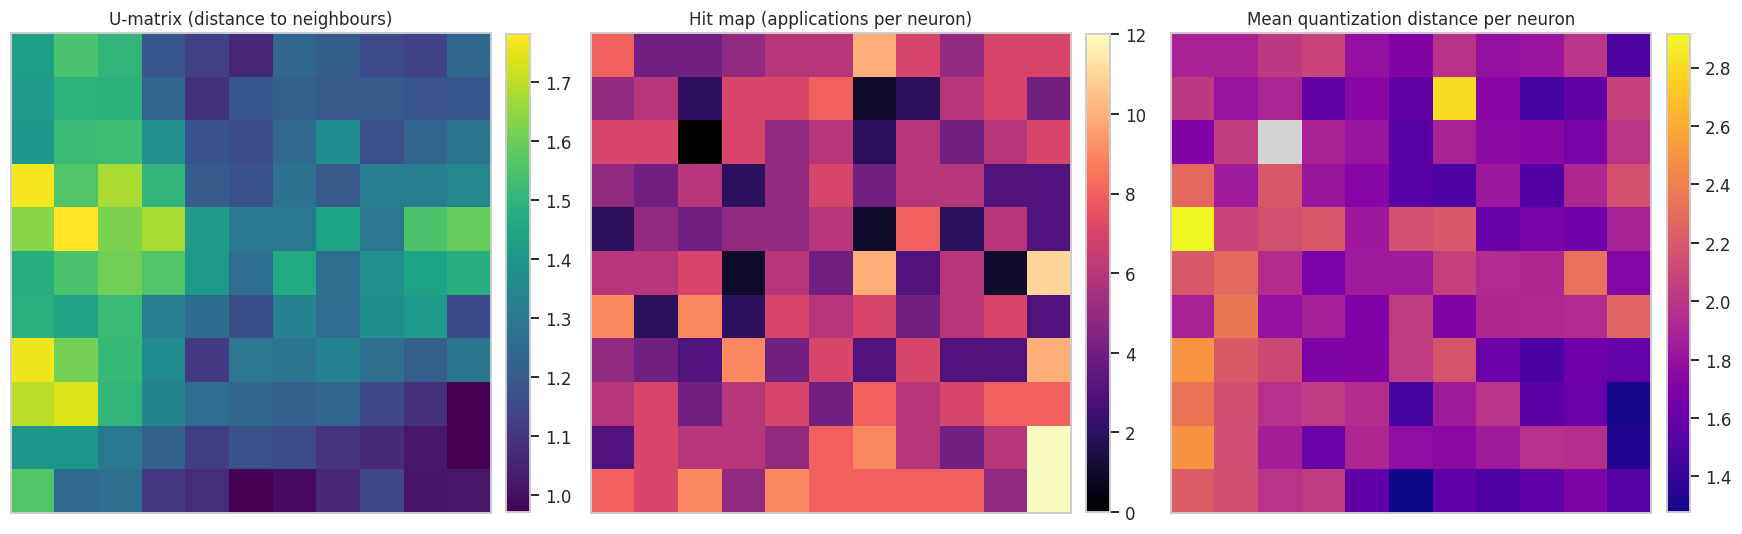

In [12]:
def draw_map(ax, values, title, cmap="viridis", **kwargs):
    cmap = plt.get_cmap(cmap).copy()
    cmap.set_bad("lightgrey")
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, **kwargs)
    ax.set_title(title, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
    return image


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
draw_map(axes[0], som.u_matrix(), "U-matrix (distance to neighbours)")
draw_map(axes[1], hits.astype(float), "Hit map (applications per neuron)", cmap="magma")
draw_map(axes[2], som.neuron_average(X_all, som_scores), "Mean quantization distance per neuron", cmap="plasma")
fig.tight_layout()
save_fig(fig, "05_som_overview_maps.png")
plt.show()

### Component planes

A component plane shows the weight of one attribute across the map. Comparing planes reveals which attributes vary together and which attribute combinations define each region. Numeric attributes are shown in standardised units, binary attributes as the probability of the value 1, and categorical attributes as the dominant category of each neuron.

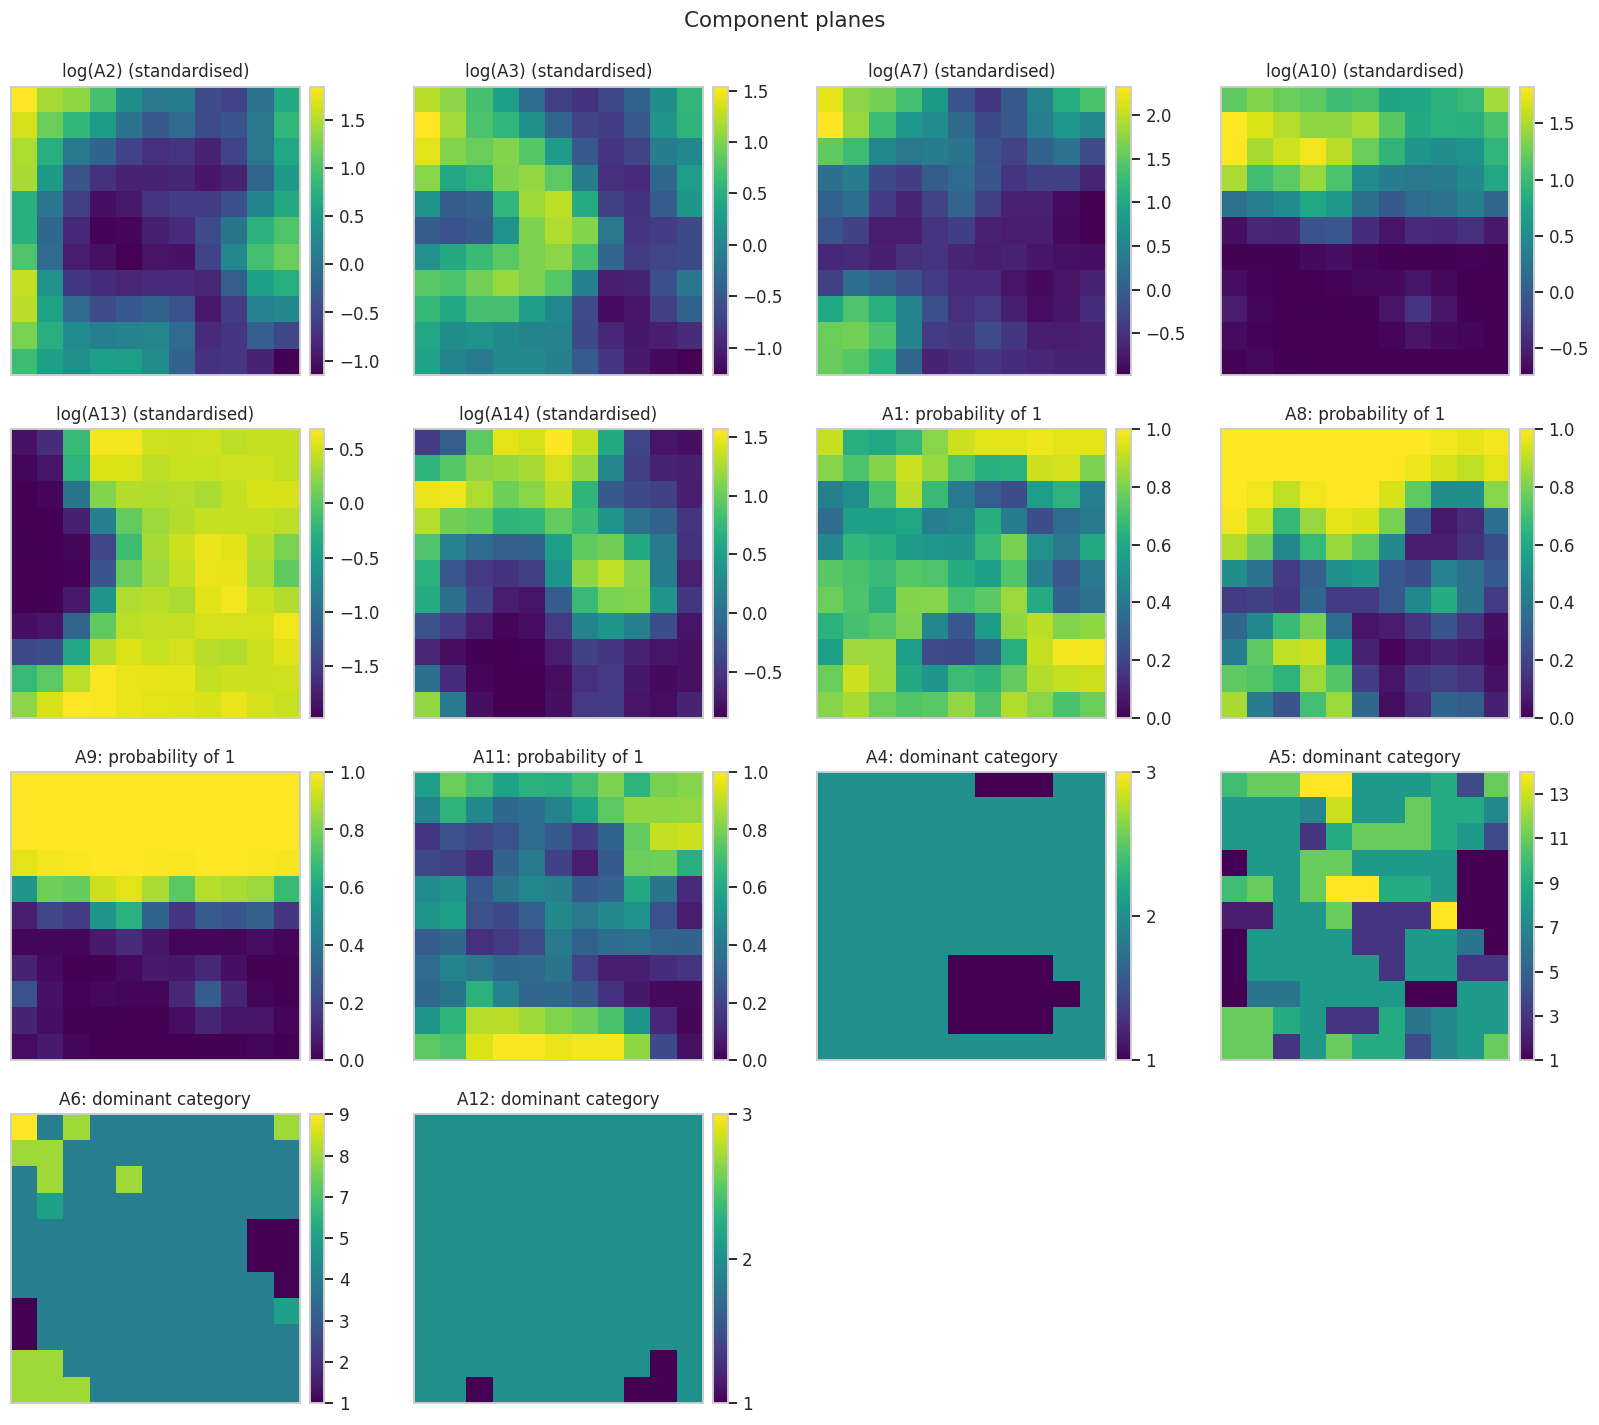

In [13]:
def plot_component_planes(som, pre):
    W = som.weights.reshape(som.rows, som.cols, -1)
    panels = [(f, "numeric") for f in NUMERIC] + [(f, "binary") for f in BINARY] + [(f, "categorical") for f in CATEGORICAL]
    fig, axes = plt.subplots(4, 4, figsize=(15, 13))
    axes = axes.ravel()
    for ax, (feature, kind) in zip(axes, panels):
        index = pre.blocks_[feature]
        if kind == "numeric":
            draw_map(ax, W[:, :, index[0]], f"{pre.feature_names_[index[0]]} (standardised)")
        elif kind == "binary":
            draw_map(ax, W[:, :, index[0]] / pre.binary_scale, f"{feature}: probability of 1", vmin=0, vmax=1)
        else:
            levels = pre.levels_[feature]
            image = ax.imshow(W[:, :, index].argmax(axis=-1), cmap="viridis", vmin=0, vmax=len(levels) - 1)
            ax.set_title(f"{feature}: dominant category", fontsize=11)
            ax.set_xticks([])
            ax.set_yticks([])
            colorbar = plt.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
            step = max(1, len(levels) // 6)
            colorbar.set_ticks(list(range(0, len(levels), step)))
            colorbar.set_ticklabels([levels[i] for i in range(0, len(levels), step)])
    for ax in axes[len(panels):]:
        ax.axis("off")
    fig.suptitle("Component planes", y=0.995, fontsize=14)
    fig.tight_layout()
    return fig


fig = plot_component_planes(som, pre)
save_fig(fig, "06_component_planes.png")
plt.show()

**Observations.** The final map has a quantization error of 1.829 and a topographic error of 0.072, and one of its 121 neurons is empty. The component planes show that the map is organised mainly by the binary attributes `A8` and `A9` together with `A10`: the upper part of the map holds applications with `A8 = 1`, `A9 = 1` and a high `A10`, and the lower part holds applications with `A9 = 0` and `A10 = 0`. `A13` varies mostly from left to right. `A4` and `A12` are almost constant across the map and therefore contribute little to its organisation, while `A5` and `A6` are spread over many small patches.

<a class="anchor" id="secA8"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A8 · Anomaly scoring and flagged applications</p>


Applications are ranked by quantization distance, and the top share given by `flag_rate` is flagged for manual review. To make each flag actionable, the squared distance to the best-matching neuron is split by original attribute. The attributes with the largest share are reported as the **main drivers** of the flag, which tells a reviewer where an application deviates from its closest prototype.

In the data, `Class` records whether the application was approved. A flagged application that was approved is the most relevant case for fraud screening, because it was accepted despite being unusual. Such applications form the *review queue*.

In [14]:
def feature_contributions(X, som, blocks):
    """Share of each application's squared quantization distance caused by each original attribute."""
    winner, _ = som.winners(X)
    squared = (X - som.weights[winner]) ** 2
    table = pd.DataFrame({feature: squared[:, index].sum(axis=1) for feature, index in blocks.items()})
    return table.div(table.sum(axis=1).clip(lower=1e-12), axis=0)


FLAG_THRESHOLD = float(np.quantile(som_scores, 1 - FLAG_RATE))
flagged = som_scores >= FLAG_THRESHOLD
contributions = feature_contributions(X_all, som, pre.blocks_)
drivers = contributions.apply(lambda row: ", ".join(row.nlargest(3).index), axis=1)

screening = df.assign(anomaly_score=som_scores, main_drivers=drivers, flagged=flagged)
review_queue = screening[screening["flagged"] & (screening[TARGET] == 1)]
print(f"Flagged applications: {int(flagged.sum())} of {len(df)} ({FLAG_RATE:.0%}) | "
      f"approved and flagged (review queue): {len(review_queue)}")

columns = [ID_COL, "anomaly_score", "main_drivers", TARGET] + NUMERIC
display(screening.sort_values("anomaly_score", ascending=False).head(15)[columns].round(2).reset_index(drop=True))

Flagged applications: 35 of 690 (5%) | approved and flagged (review queue): 19


,CustomerID,anomaly_score,main_drivers,Class,A2,A3,A7,A10,A13,A14
0,15790113,3.40,"A14, A12, A4",1,17.50,22.00,0.00,0,450,100001
1,15772329,3.40,"A3, A4, A14",1,28.08,15.00,0.00,0,0,13213
2,15642098,3.31,"A3, A7, A10",1,47.67,0.29,15.00,20,0,15001
3,15645820,3.25,"A2, A4, A3",1,18.08,0.38,10.00,0,300,1
4,15671293,3.11,"A2, A7, A6",0,54.83,15.50,0.00,20,152,131
5,15767264,3.08,"A9, A14, A2",0,74.83,19.00,0.04,2,0,352
6,15751167,2.96,"A3, A7, A6",1,41.33,0.00,15.00,0,0,1
7,15580579,2.91,"A2, A5, A3",0,43.25,25.21,0.21,1,760,91
8,15687688,2.89,"A4, A10, A6",1,21.67,11.50,0.00,11,0,1
9,15764922,2.88,"A14, A4, A5",0,22.50,11.50,1.50,0,0,4001


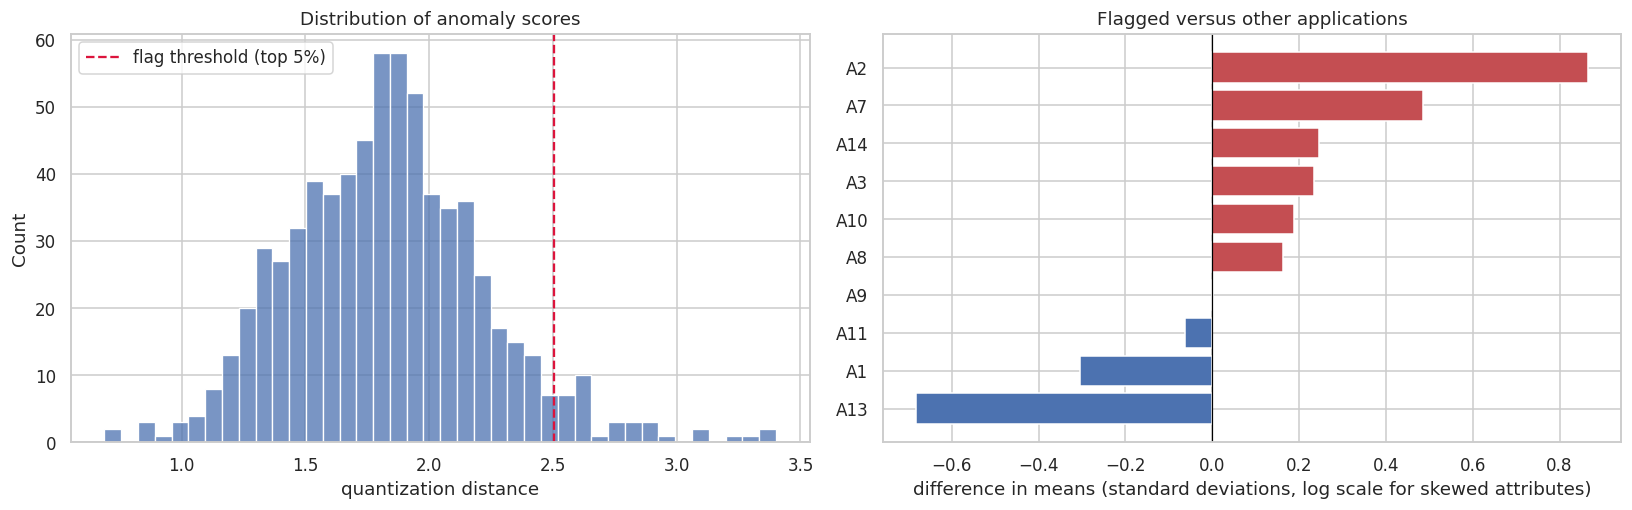

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

sns.histplot(som_scores, bins=40, color="#4C72B0", ax=axes[0])
axes[0].axvline(FLAG_THRESHOLD, color="crimson", linestyle="--", label=f"flag threshold (top {FLAG_RATE:.0%})")
axes[0].set_title("Distribution of anomaly scores")
axes[0].set_xlabel("quantization distance")
axes[0].legend()

profile = df[NUMERIC + BINARY].copy()
profile[pre.log_cols_] = np.log1p(profile[pre.log_cols_])
difference = (profile[flagged].mean() - profile[~flagged].mean()) / profile.std()
difference = difference.sort_values()
axes[1].barh(difference.index, difference.values, color=np.where(difference.values > 0, "#C44E52", "#4C72B0"))
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Flagged versus other applications")
axes[1].set_xlabel("difference in means (standard deviations, log scale for skewed attributes)")

fig.tight_layout()
save_fig(fig, "07_anomaly_scores_and_profile.png")
plt.show()

**Observations.** The anomaly scores form a single, roughly bell-shaped distribution with a longer right tail, so there is no natural gap between normal and anomalous applications. The top-5% threshold (a score of about 2.5) is a review-capacity decision, not a statistical boundary. Of the 35 flagged applications, 19 were approved and form the review queue.

On average, flagged applications have higher `A2` and `A7` (0.9 and 0.5 standard deviations above the rest) and lower `A13` (0.7 below). The drivers differ from one application to the next: among the 15 highest-scoring applications, `A3`, `A2`, `A4` and `A10` are named most often.

<a class="anchor" id="secA9"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A9 · Map regions and application outcome</p>


The prototypes are grouped into regions with k-means on the codebook vectors, a standard way to turn a SOM into a segmentation. The number of regions is chosen with the silhouette score. The outcome is overlaid afterwards for interpretation only. It played no part in training.

Silhouette score by number of regions: {2: 0.261, 3: 0.238, 4: 0.253, 5: 0.237, 6: 0.247, 7: 0.241, 8: 0.241}
Selected number of regions: 2


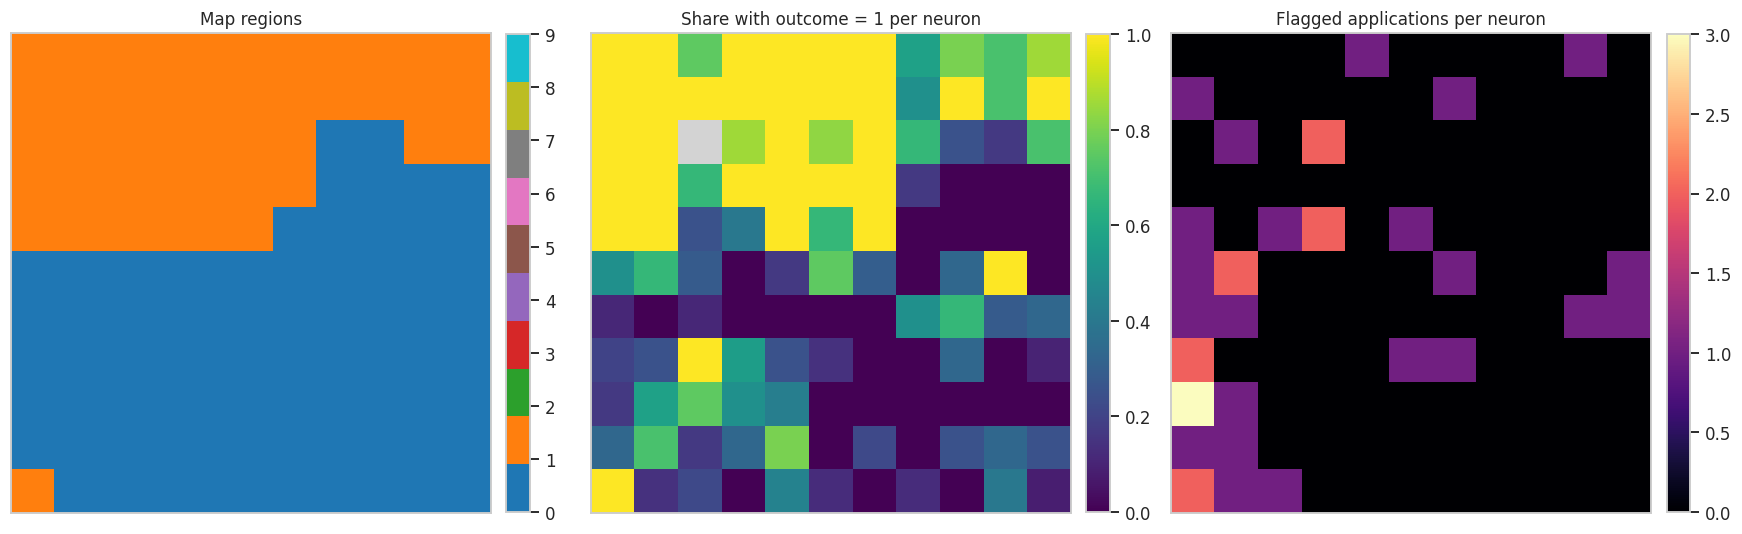

,applications,outcome_share,flagged_share,A2,A3,A7,A10,A13,A14,A1,A8,A9,A11
region,,,,,,,,,,,,,
0,451,0.22,0.05,30.08,3.81,1.39,0.31,196.52,469.63,0.68,0.30,0.15,0.43
1,239,0.87,0.06,34.38,6.54,3.80,6.35,160.42,2053.91,0.67,0.94,0.96,0.52


In [16]:
silhouette = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(som.weights)
    silhouette[k] = silhouette_score(som.weights, labels)
BEST_K = max(silhouette, key=silhouette.get)
print("Silhouette score by number of regions:", {k: round(v, 3) for k, v in silhouette.items()})
print(f"Selected number of regions: {BEST_K}")

neuron_region = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED).fit_predict(som.weights)
winner, _ = som.winners(X_all)
region = neuron_region[winner]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
draw_map(axes[0], neuron_region.reshape(som.rows, som.cols).astype(float), "Map regions", cmap="tab10", vmin=0, vmax=9)
draw_map(axes[1], som.neuron_average(X_all, df[TARGET].to_numpy(float)), "Share with outcome = 1 per neuron", vmin=0, vmax=1)
draw_map(axes[2], som.hit_map(X_all[flagged]).astype(float), "Flagged applications per neuron", cmap="magma")
fig.tight_layout()
save_fig(fig, "08_regions_and_outcome.png")
plt.show()

region_profile = (df.assign(region=region, flagged=flagged)
                  .groupby("region")
                  .agg(applications=("region", "size"), outcome_share=(TARGET, "mean"), flagged_share=("flagged", "mean"),
                       **{c: (c, "mean") for c in NUMERIC + BINARY})
                  .round(2))
display(region_profile)

**Observations.** The silhouette score is highest for two regions (0.261) and low for every number of regions tested (0.24 to 0.26), so the map shows only coarse cluster structure. The two regions separate applications with `A8 = 1` and `A9 = 1` (239 applications, 87% with outcome 1; `A8` and `A9` equal 1 in 94% and 96% of them) from the rest (451 applications, 22% with outcome 1). Flagged applications are spread over both regions (6% and 5%), so the anomaly scores do not simply reflect the region of an application.

<a class="anchor" id="secA10"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A10 · Neural network detectors</p>


Three neural detectors provide a comparison with the SOM. They are trained without labels on the same preprocessed inputs, and each assigns an anomaly score to every application.

| Detector | Idea | Anomaly score |
|---|---|---|
| **Autoencoder** | Compresses an application into a small code and reconstructs it. Typical applications are reconstructed well. | Squared reconstruction error |
| **Variational Autoencoder (VAE)** | Learns a probabilistic code regularised towards a standard normal distribution. | Negative evidence lower bound: reconstruction error plus KL divergence, using the encoder mean |
| **Deep SVDD** | Maps typical applications into a small hypersphere in a learned space. The encoder is pretrained as an autoencoder and has no bias terms, which prevents a trivial collapse. | Squared distance to the hypersphere centre |

Architectures and training settings are fixed in advance, with a small bottleneck of 8 dimensions. They are not tuned on the benchmark of A11, so the comparison does not favour any detector through its own tuning. The models are small, so a single GPU (or the CPU) is sufficient.

In [17]:
import torch
from torch import nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {DEVICE} | visible GPUs: {torch.cuda.device_count()}")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def mlp(sizes, bias=True):
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1], bias=bias))
        if i < len(sizes) - 2:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)


def train_model(model, loss_fn, data, epochs, batch_size, lr, weight_decay, seed):
    """Mini-batch Adam training. Returns the mean loss of every epoch."""
    rng = np.random.default_rng(seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = []
    model.train()
    for _ in range(int(epochs)):
        order = torch.as_tensor(rng.permutation(len(data)), device=DEVICE)
        running = 0.0
        for start in range(0, len(data), batch_size):
            batch = data[order[start:start + batch_size]]
            optimiser.zero_grad()
            loss = loss_fn(model, batch)
            loss.backward()
            optimiser.step()
            running += loss.item() * len(batch)
        history.append(running / len(data))
    model.eval()
    return history


class TorchDetector:
    """Common fit / score / save / load interface for the neural detectors."""
    name = "detector"
    DEFAULTS = {"hidden": 64, "latent": 8, "epochs": 200, "batch_size": 64, "lr": 1e-3, "weight_decay": 1e-5}

    def __init__(self, input_dim, seed=0, **params):
        self.input_dim, self.seed = int(input_dim), int(seed)
        self.params = {**self.DEFAULTS, **params}
        self.history = {}

    def _tensor(self, X):
        return torch.as_tensor(np.asarray(X), dtype=torch.float32, device=DEVICE)

    def save(self, path):
        torch.save({"input_dim": self.input_dim, "seed": self.seed, "params": self.params,
                    "state": self._get_state(), "history": self.history}, path)

    @classmethod
    def load(cls, path):
        blob = torch.load(path, map_location=DEVICE, weights_only=True)
        detector = cls(blob["input_dim"], blob["seed"], **blob["params"])
        detector._build()
        detector._set_state(blob["state"])
        detector.history = blob["history"]
        return detector


class AutoencoderNet(nn.Module):
    def __init__(self, d, hidden, latent, bias=True):
        super().__init__()
        self.encoder = mlp([d, hidden, hidden // 2, latent], bias=bias)
        self.decoder = mlp([latent, hidden // 2, hidden, d])

    def forward(self, x):
        return self.decoder(self.encoder(x))


class AutoencoderDetector(TorchDetector):
    name = "Autoencoder"

    def _build(self):
        self.model = AutoencoderNet(self.input_dim, self.params["hidden"], self.params["latent"]).to(DEVICE)

    def fit(self, X):
        set_seed(self.seed)
        self._build()
        p = self.params
        loss_fn = lambda model, x: ((model(x) - x) ** 2).sum(dim=1).mean()
        self.history = {"loss": train_model(self.model, loss_fn, self._tensor(X), p["epochs"],
                                            p["batch_size"], p["lr"], p["weight_decay"], self.seed)}
        return self

    @torch.no_grad()
    def score(self, X):
        x = self._tensor(X)
        return ((self.model(x) - x) ** 2).sum(dim=1).cpu().numpy()

    def _get_state(self):
        return {"model": self.model.state_dict()}

    def _set_state(self, state):
        self.model.load_state_dict(state["model"])
        self.model.eval()


class VAENet(nn.Module):
    def __init__(self, d, hidden, latent):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, hidden // 2), nn.ReLU())
        self.mu = nn.Linear(hidden // 2, latent)
        self.logvar = nn.Linear(hidden // 2, latent)
        self.decoder = mlp([latent, hidden // 2, hidden, d])

    def encode(self, x):
        h = self.body(x)
        return self.mu(h), self.logvar(h)


def vae_terms(model, x, sample):
    mu, logvar = model.encode(x)
    z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar) if sample else mu
    reconstruction = ((model.decoder(z) - x) ** 2).sum(dim=1)
    kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)
    return reconstruction, kl


class VAEDetector(TorchDetector):
    name = "VAE"
    DEFAULTS = {**TorchDetector.DEFAULTS, "beta": 1.0}

    def _build(self):
        self.model = VAENet(self.input_dim, self.params["hidden"], self.params["latent"]).to(DEVICE)

    def fit(self, X):
        set_seed(self.seed)
        self._build()
        p = self.params

        def loss_fn(model, x):
            reconstruction, kl = vae_terms(model, x, sample=True)
            return (reconstruction + p["beta"] * kl).mean()

        self.history = {"loss": train_model(self.model, loss_fn, self._tensor(X), p["epochs"],
                                            p["batch_size"], p["lr"], p["weight_decay"], self.seed)}
        return self

    @torch.no_grad()
    def score(self, X):
        reconstruction, kl = vae_terms(self.model, self._tensor(X), sample=False)
        return (reconstruction + self.params["beta"] * kl).cpu().numpy()

    def _get_state(self):
        return {"model": self.model.state_dict()}

    def _set_state(self, state):
        self.model.load_state_dict(state["model"])
        self.model.eval()


class DeepSVDDDetector(TorchDetector):
    name = "Deep SVDD"
    DEFAULTS = {**TorchDetector.DEFAULTS, "pretrain_epochs": 100, "pretrain_lr": 1e-3}

    def _build(self):
        p = self.params
        self.autoencoder = AutoencoderNet(self.input_dim, p["hidden"], p["latent"], bias=False).to(DEVICE)
        self.center = torch.zeros(p["latent"], device=DEVICE)

    def fit(self, X):
        set_seed(self.seed)
        self._build()
        p = self.params
        data = self._tensor(X)

        reconstruction_loss = lambda model, x: ((model(x) - x) ** 2).sum(dim=1).mean()
        pretrain = train_model(self.autoencoder, reconstruction_loss, data, p["pretrain_epochs"],
                               p["batch_size"], p["pretrain_lr"], p["weight_decay"], self.seed)

        encoder = self.autoencoder.encoder
        with torch.no_grad():
            center = encoder(data).mean(dim=0)
        eps = 0.1
        center[(center.abs() < eps) & (center < 0)] = -eps
        center[(center.abs() < eps) & (center >= 0)] = eps
        self.center = center

        svdd_loss = lambda model, x: ((model(x) - self.center) ** 2).sum(dim=1).mean()
        loss = train_model(encoder, svdd_loss, data, p["epochs"], p["batch_size"], p["lr"],
                           p["weight_decay"], self.seed + 1)
        self.history = {"pretrain_loss": pretrain, "loss": loss}
        return self

    @torch.no_grad()
    def score(self, X):
        return ((self.autoencoder.encoder(self._tensor(X)) - self.center) ** 2).sum(dim=1).cpu().numpy()

    def _get_state(self):
        return {"encoder": self.autoencoder.encoder.state_dict(), "center": self.center}

    def _set_state(self, state):
        self.autoencoder.encoder.load_state_dict(state["encoder"])
        self.autoencoder.encoder.eval()
        self.center = state["center"].to(DEVICE)

PyTorch 2.4.0 | device: cuda | visible GPUs: 2


In [18]:
nn_cfg = CONFIG["neural"]
base = dict(hidden=nn_cfg["hidden"], latent=nn_cfg["latent"], batch_size=nn_cfg["batch_size"],
            weight_decay=nn_cfg["weight_decay"])
AE_PARAMS = {**base, "epochs": nn_cfg["epochs"], "lr": nn_cfg["lr"]}
VAE_PARAMS = {**AE_PARAMS, "beta": nn_cfg["vae_beta"]}
SVDD_PARAMS = {**base, "pretrain_epochs": nn_cfg["svdd_pretrain_epochs"], "pretrain_lr": nn_cfg["lr"],
               "epochs": nn_cfg["svdd_epochs"], "lr": nn_cfg["svdd_lr"]}

NEURAL_MODELS = {
    "Autoencoder": (AutoencoderDetector, AE_PARAMS),
    "VAE": (VAEDetector, VAE_PARAMS),
    "Deep SVDD": (DeepSVDDDetector, SVDD_PARAMS),
}

# Factories (input_dim, seed) -> untrained detector, shared by the benchmark and the stability study.
DETECTORS = {"SOM": lambda d, seed: SOMDetector(d, seed, **SOM_PARAMS)}
for _name, (_cls, _params) in NEURAL_MODELS.items():
    DETECTORS[_name] = (lambda d, seed, c=_cls, p=_params: c(d, seed, **p))

final_scores = {"SOM": som_scores}
final_models = {}
for name, (cls, params) in NEURAL_MODELS.items():
    file = "model_" + name.lower().replace(" ", "_") + ".pt"
    path = store.lookup(file)
    if path is not None:
        detector = cls.load(path)
        print(f"Loaded saved model: {file}")
    else:
        start = time.time()
        detector = cls(X_all.shape[1], SEED, **params).fit(X_all)
        detector.save(store.path(file))
        print(f"Trained {name} in {time.time() - start:.1f}s")
    final_models[name] = detector
    final_scores[name] = detector.score(X_all)

scores_table = pd.DataFrame({ID_COL: df[ID_COL], TARGET: df[TARGET],
                             **{f"score_{name}": scores for name, scores in final_scores.items()}})
scores_table.to_csv(store.path("anomaly_scores.csv"), index=False)
display(scores_table.describe().T[["mean", "std", "min", "max"]].round(3))

Loaded saved model: model_autoencoder.pt
Loaded saved model: model_vae.pt
Loaded saved model: model_deep_svdd.pt


,mean,std,min,max
CustomerID,1.569047e+07,71506.474,1.556571e+07,1.581544e+07
Class,4.450000e-01,0.497,0.000000e+00,1.000000e+00
score_SOM,1.829000e+00,0.397,6.880000e-01,3.401000e+00
score_Autoencoder,1.657000e+00,0.722,3.020000e-01,5.477000e+00
score_VAE,6.712000e+00,2.093,2.931000e+00,2.064000e+01
score_Deep SVDD,3.400000e-02,0.033,2.000000e-03,2.740000e-01


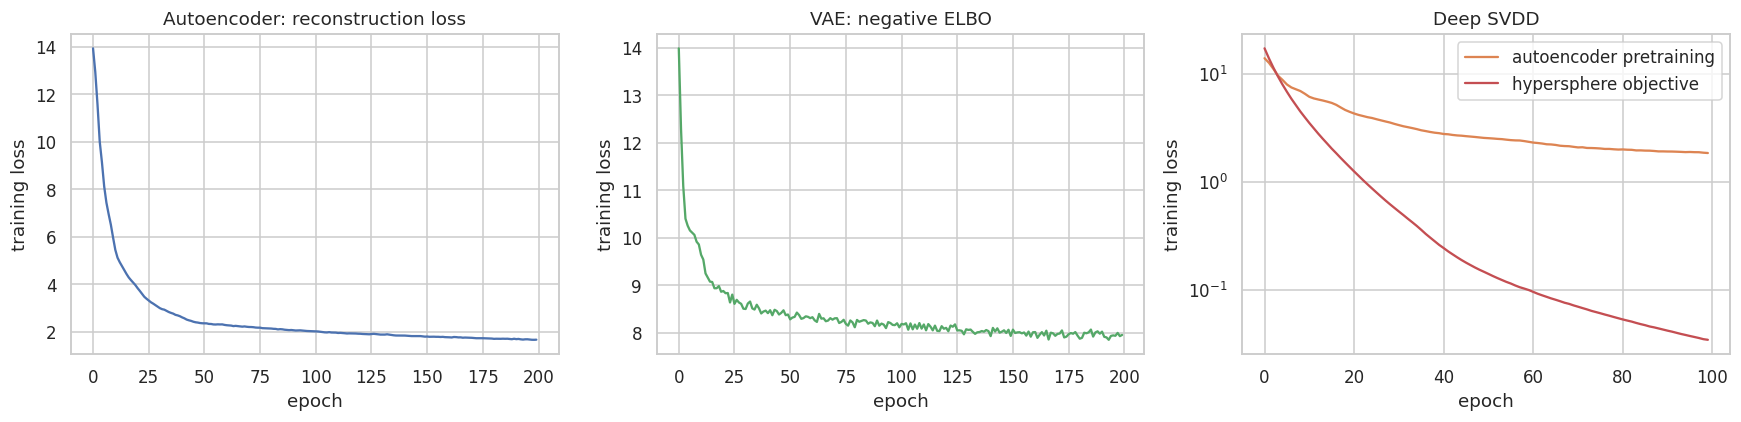

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(final_models["Autoencoder"].history["loss"], color="#4C72B0")
axes[0].set_title("Autoencoder: reconstruction loss")
axes[1].plot(final_models["VAE"].history["loss"], color="#55A868")
axes[1].set_title("VAE: negative ELBO")
axes[2].plot(final_models["Deep SVDD"].history["pretrain_loss"], label="autoencoder pretraining", color="#DD8452")
axes[2].plot(final_models["Deep SVDD"].history["loss"], label="hypersphere objective", color="#C44E52")
axes[2].set_title("Deep SVDD")
axes[2].set_yscale("log")
axes[2].legend()
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("training loss")
fig.tight_layout()
save_fig(fig, "09_training_curves.png")
plt.show()

**Observations.** The autoencoder loss is still decreasing slowly after 200 epochs, so the network keeps fitting the training applications more closely. In Deep SVDD the hypersphere objective keeps shrinking towards zero over all 100 epochs. Both observations are relevant for the stability results in A12.

<a class="anchor" id="secA11"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A11 · Benchmark with injected anomalies</p>


Because the data has no fraud labels, detectors are compared on a controlled task. In 5-fold cross-validation, repeated three times, every detector is trained on the training folds only, including the preprocessing. Each held-out fold is then extended with one synthetic anomaly per application. Two anomaly types represent common patterns in application fraud:

| Anomaly type | Construction | What it represents |
|---|---|---|
| **Inconsistent profile** | Four of the 14 attributes are replaced with the values of other randomly chosen applications | Every single value is plausible, but the combination is not (for example fabricated or mixed identities) |
| **Extreme values** | Two numeric attributes are raised to 1.5 to 3 times their 99th percentile | Implausibly large amounts |

Detectors are evaluated by the ROC-AUC between real held-out applications and the synthetic anomalies, and by the average precision at a 10% anomaly share (the anomalies are re-weighted to that share). A score of 0.5 ROC-AUC corresponds to random ranking.

The synthetic anomalies are a proxy for fraud patterns. They test whether a detector recognises applications that deviate from the learned structure of normal data, not whether it finds real fraud.

In [20]:
def inject_inconsistent(test, train, k, rng):
    """Replace k random attributes of every application with values from random training applications."""
    values = test[FEATURES].to_numpy(float).copy()
    donors = train[FEATURES].to_numpy(float)
    n, d = values.shape
    columns = np.argsort(rng.random((n, d)), axis=1)[:, :k]
    donor_rows = rng.integers(0, len(donors), size=(n, k))
    values[np.arange(n)[:, None], columns] = donors[donor_rows, columns]
    return pd.DataFrame(values, columns=FEATURES)


def inject_extreme(test, train, k, factor, rng):
    """Raise k random numeric attributes of every application to 1.5 to 3 times the 99th percentile."""
    values = test[FEATURES].to_numpy(float).copy()
    numeric_positions = np.array([FEATURES.index(c) for c in NUMERIC])
    q99 = np.quantile(train[NUMERIC].to_numpy(float), 0.99, axis=0)
    q99 = np.where(q99 > 0, q99, train[NUMERIC].to_numpy(float).max(axis=0))
    n = len(values)
    picked = np.argsort(rng.random((n, len(NUMERIC))), axis=1)[:, :k]
    target = q99[picked] * rng.uniform(factor[0], factor[1], size=(n, k))
    columns = numeric_positions[picked]
    rows = np.arange(n)[:, None]
    values[rows, columns] = np.maximum(values[rows, columns], target)
    return pd.DataFrame(values, columns=FEATURES)


def run_benchmark(frame, detectors, cfg, seed):
    features = frame[FEATURES].reset_index(drop=True)
    results = []
    for repeat in range(cfg["n_repeats"]):
        splitter = KFold(cfg["n_splits"], shuffle=True, random_state=seed + repeat)
        for fold, (tr, te) in enumerate(splitter.split(features)):
            run_seed = seed + 100 * repeat + fold
            rng = np.random.default_rng(run_seed)
            train, test = features.iloc[tr], features.iloc[te]
            prep = Preprocessor(NUMERIC, BINARY, CATEGORICAL, CONFIG["skew_threshold"]).fit(train)
            X_train, X_test = prep.transform(train), prep.transform(test)
            anomalies = {
                "Inconsistent profile": prep.transform(inject_inconsistent(test, train, cfg["mixed_features"], rng)),
                "Extreme values": prep.transform(inject_extreme(test, train, cfg["extreme_features"], cfg["extreme_factor"], rng)),
            }
            for name, factory in detectors.items():
                detector = factory(X_train.shape[1], run_seed).fit(X_train)
                normal = detector.score(X_test)
                for kind, X_anomaly in anomalies.items():
                    anomalous = detector.score(X_anomaly)
                    truth = np.r_[np.zeros(len(normal)), np.ones(len(anomalous))]
                    scores = np.r_[normal, anomalous]
                    share = cfg["contamination"]
                    weight = share / (1 - share) * len(normal) / len(anomalous)
                    weights = np.r_[np.ones(len(normal)), np.full(len(anomalous), weight)]
                    results.append({"repeat": repeat, "fold": fold, "model": name, "anomaly_type": kind,
                                    "roc_auc": roc_auc_score(truth, scores),
                                    "average_precision": average_precision_score(truth, scores, sample_weight=weights)})
            print(f"  repeat {repeat + 1}/{cfg['n_repeats']}, fold {fold + 1}/{cfg['n_splits']} done")
    return pd.DataFrame(results)


start = time.time()
benchmark = cached_table("benchmark_results.csv", lambda: run_benchmark(df, DETECTORS, CONFIG["benchmark"], SEED))
print(f"Benchmark ready ({time.time() - start:.0f}s)")

MODEL_ORDER = list(DETECTORS)
summary_rows = []
for (model, kind), group in benchmark.groupby(["model", "anomaly_type"]):
    summary_rows.append({"model": model, "anomaly type": kind,
                         "ROC-AUC": f"{group['roc_auc'].mean():.3f} ± {group['roc_auc'].std():.3f}",
                         "average precision": f"{group['average_precision'].mean():.3f} ± {group['average_precision'].std():.3f}"})
benchmark_summary = pd.DataFrame(summary_rows)
benchmark_summary["model"] = pd.Categorical(benchmark_summary["model"], MODEL_ORDER)
display(benchmark_summary.sort_values(["anomaly type", "model"]).reset_index(drop=True))

Loaded saved result: benchmark_results.csv
Benchmark ready (0s)


,model,anomaly type,ROC-AUC,average precision
0,SOM,Extreme values,0.984 ± 0.004,0.910 ± 0.019
1,Autoencoder,Extreme values,0.914 ± 0.018,0.695 ± 0.064
2,VAE,Extreme values,0.987 ± 0.003,0.911 ± 0.031
3,Deep SVDD,Extreme values,0.952 ± 0.016,0.794 ± 0.071
4,SOM,Inconsistent profile,0.636 ± 0.019,0.167 ± 0.017
5,Autoencoder,Inconsistent profile,0.665 ± 0.026,0.228 ± 0.036
6,VAE,Inconsistent profile,0.606 ± 0.019,0.152 ± 0.016
7,Deep SVDD,Inconsistent profile,0.649 ± 0.029,0.254 ± 0.059


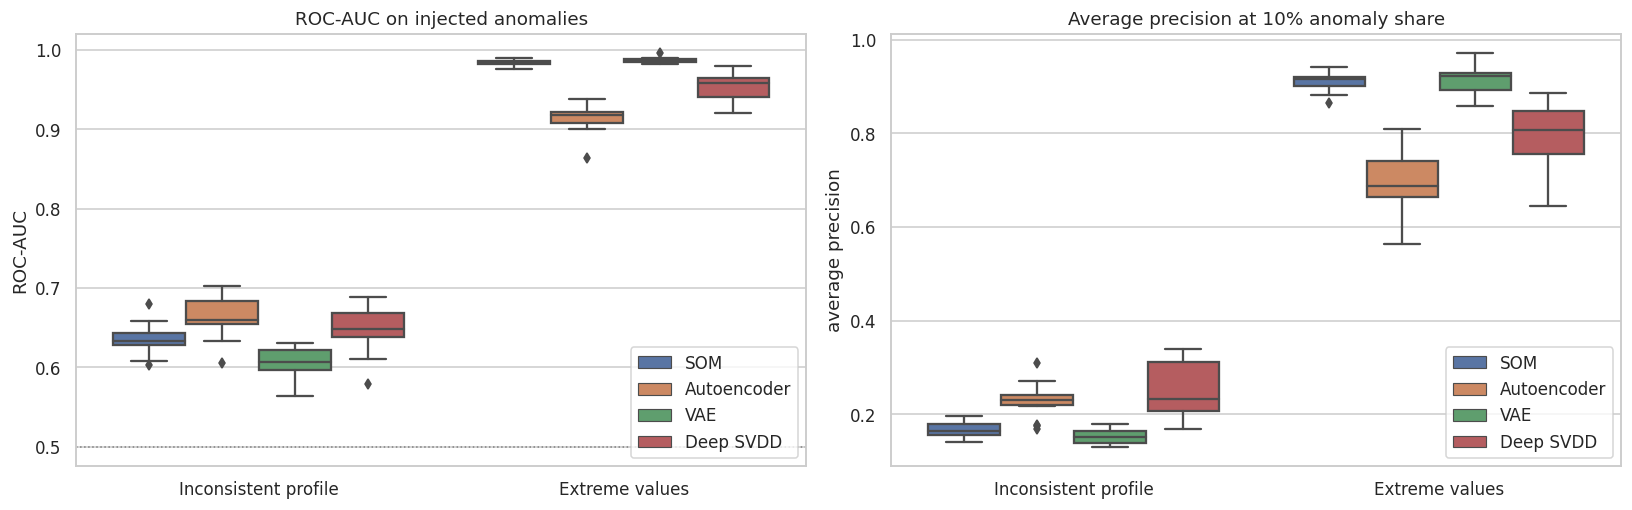

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, metric, title in zip(axes, ["roc_auc", "average_precision"],
                             ["ROC-AUC on injected anomalies", "Average precision at 10% anomaly share"]):
    sns.boxplot(data=benchmark, x="anomaly_type", y=metric, hue="model", hue_order=MODEL_ORDER,
                palette="deep", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(METRIC_LABELS[metric])
    ax.legend(title="", loc="lower right")
axes[0].axhline(0.5, color="grey", linestyle=":", linewidth=1)
fig.tight_layout()
save_fig(fig, "10_benchmark_injected_anomalies.png")
plt.show()

### Sensitivity to the SOM grid size

The grid size was set by a rule of thumb and not tuned on this benchmark. To show how much the choice matters, the same benchmark is run for SOMs of different sizes (one repeat of 5-fold cross-validation, same radius and learning rate). This analysis is for reporting only and does not change the selected map.

Loaded saved result: som_grid_sensitivity.csv


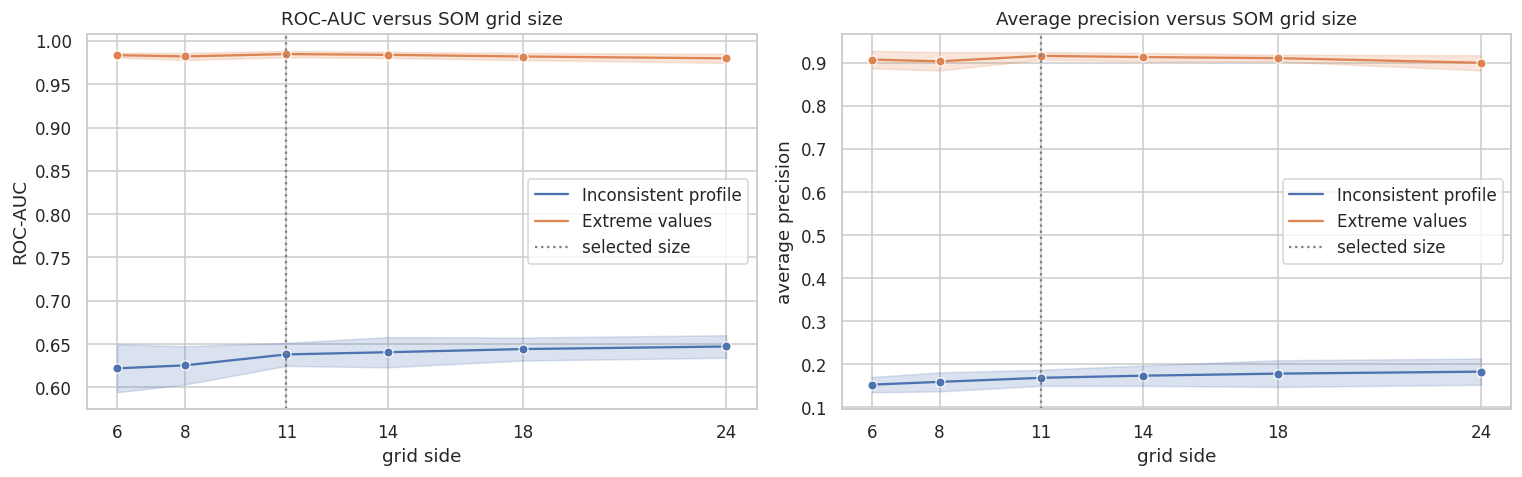

In [22]:
def som_grid_sensitivity():
    detectors = {f"SOM {s}x{s}": (lambda d, seed, s=s: SOMDetector(d, seed, **{**SOM_PARAMS, "side": s}))
                 for s in CONFIG["som"]["sensitivity_sides"]}
    return run_benchmark(df, detectors, {**CONFIG["benchmark"], "n_repeats": 1}, SEED)


sensitivity = cached_table("som_grid_sensitivity.csv", som_grid_sensitivity)
sensitivity["grid side"] = sensitivity["model"].str.extract(r"SOM (\d+)x")[0].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, title in zip(axes, ["roc_auc", "average_precision"],
                             ["ROC-AUC versus SOM grid size", "Average precision versus SOM grid size"]):
    sns.lineplot(data=sensitivity, x="grid side", y=metric, hue="anomaly_type", marker="o", errorbar="sd", ax=ax)
    ax.axvline(BEST_SIDE, color="grey", linestyle=":", label="selected size")
    ax.set_title(title)
    ax.set_xticks(sorted(sensitivity["grid side"].unique()))
    ax.set_ylabel(METRIC_LABELS[metric])
    ax.legend(title="")
fig.tight_layout()
save_fig(fig, "10b_som_grid_size_sensitivity.png")
plt.show()

**Results of the benchmark (A11).**

- **Extreme values.** All detectors recognise implausibly large amounts. The VAE (ROC-AUC 0.987) and the SOM (0.984) are best, with the same average precision of 0.91. Deep SVDD (0.952) and the autoencoder (0.914) are weaker.
- **Inconsistent profiles.** All detectors are weak here, with ROC-AUC between 0.61 and 0.67 and average precision between 0.15 and 0.25 (chance level at a 10% anomaly share: 0.10). The autoencoder (0.665) and Deep SVDD (0.649) are slightly ahead of the SOM (0.636) and the VAE (0.606), but these differences are comparable to the fold-to-fold standard deviation of 0.02 to 0.03. This is consistent with the weak dependence between attributes seen in A3: when most attributes are nearly independent, replacing a few of them with values from other applications often produces a profile that is still plausible.
- **Overall.** Averaged over both anomaly types, the detectors are close: mean ROC-AUC 0.810 for the SOM, 0.800 for Deep SVDD, 0.797 for the VAE and 0.790 for the autoencoder.
- **Grid size.** The SOM's performance on extreme values is flat from a 6 x 6 to a 24 x 24 grid (ROC-AUC about 0.98), and on inconsistent profiles it rises slowly from about 0.62 to 0.65. The selected 11 x 11 map is not a sensitive choice.

<a class="anchor" id="secA12"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A12 · Stability and agreement</p>


**Stability.** Each detector is trained with several random seeds on all applications. If the screening is reliable, the seeds should rank the applications in the same way. This is measured by the Spearman rank correlation between the anomaly scores of two seeds and by the overlap (Jaccard index) of the flagged sets.

**Agreement.** Averaging the rank-normalised scores over seeds gives one consensus score per detector. The correlation and the overlap of flagged sets between detectors show how much the different principles agree on which applications are unusual.

In [23]:
def top_set(scores, rate):
    k = max(1, int(round(rate * len(scores))))
    return set(np.argsort(scores)[-k:])


def jaccard(a, b, rate):
    first, second = top_set(a, rate), top_set(b, rate)
    return len(first & second) / len(first | second)


def build_seed_scores(X, n_seeds):
    scores = {}
    for name, factory in DETECTORS.items():
        columns = [final_scores[name]]
        for k in range(1, n_seeds):
            columns.append(factory(X.shape[1], SEED + k).fit(X).score(X))
        scores[name] = np.column_stack(columns)
        print(f"  {name}: {n_seeds} seeds ready")
    return scores


def seed_scores_table():
    scores = build_seed_scores(X_all, CONFIG["stability_seeds"])
    return pd.DataFrame({f"{name}__{k}": matrix[:, k] for name, matrix in scores.items() for k in range(matrix.shape[1])})


raw = cached_table("seed_scores.csv", seed_scores_table)
seed_scores = {name: raw[[c for c in raw.columns if c.startswith(f"{name}__")]].to_numpy() for name in DETECTORS}

stability_rows = []
for name, matrix in seed_scores.items():
    pairs = [(i, j) for i in range(matrix.shape[1]) for j in range(i + 1, matrix.shape[1])]
    correlations = [rank_correlation(matrix[:, i], matrix[:, j]) for i, j in pairs]
    overlaps = [jaccard(matrix[:, i], matrix[:, j], FLAG_RATE) for i, j in pairs]
    stability_rows.append({"model": name, "seeds": matrix.shape[1],
                           "mean rank correlation": np.mean(correlations), "minimum rank correlation": np.min(correlations),
                           f"mean overlap of top {FLAG_RATE:.0%}": np.mean(overlaps)})
stability = pd.DataFrame(stability_rows).round(3)
stability.to_csv(store.path("stability_summary.csv"), index=False)
display(stability)

Loaded saved result: seed_scores.csv


,model,seeds,mean rank correlation,minimum rank correlation,mean overlap of top 5%
0,SOM,10,0.814,0.789,0.469
1,Autoencoder,10,0.657,0.560,0.219
2,VAE,10,0.980,0.958,0.705
3,Deep SVDD,10,0.291,0.176,0.119


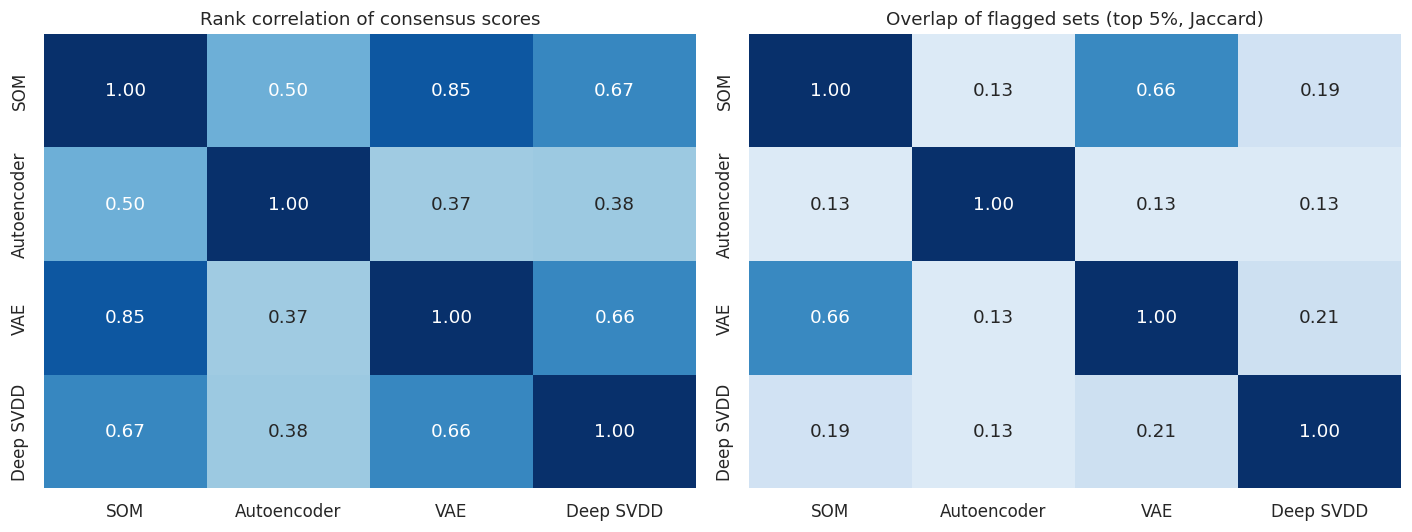

In [24]:
consensus = {name: pd.DataFrame(matrix).rank(pct=True).mean(axis=1).to_numpy() for name, matrix in seed_scores.items()}
names = list(consensus)

correlation_matrix = pd.DataFrame({a: {b: rank_correlation(consensus[a], consensus[b]) for b in names} for a in names})
overlap_matrix = pd.DataFrame({a: {b: jaccard(consensus[a], consensus[b], FLAG_RATE) for b in names} for a in names})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Rank correlation of consensus scores")
sns.heatmap(overlap_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title(f"Overlap of flagged sets (top {FLAG_RATE:.0%}, Jaccard)")
fig.tight_layout()
save_fig(fig, "11_detector_agreement.png")
plt.show()

**Stability.** Across 10 seeds, the VAE is the most stable detector (mean rank correlation 0.98, about 70% overlap of the flagged top 5%), followed by the SOM (0.81, 47%), the autoencoder (0.66, 22%) and Deep SVDD (0.29, 12%). The SOM ranks the applications consistently overall, but about half of its flagged set changes between seeds, so applications near the threshold are not reliably identified by a single map. Deep SVDD is only weakly consistent between seeds, which may be related to the shrinking hypersphere objective seen in A10. The benchmark shows that it still detects extreme values, because those lie far from the centre under any seed, but a single Deep SVDD run should not be used for ranking.

**Agreement.** The SOM and the VAE agree most (rank correlation 0.85 between their consensus scores, 66% overlap of the flagged sets). Deep SVDD agrees moderately with both (0.66 to 0.67), and the autoencoder agrees least with all others (0.37 to 0.50, 13% overlap).

**Implication.** Averaging the scores of several seeds, as done for the consensus scores here, is advisable for any detector used for screening.

<a class="anchor" id="secA13"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A13 · Comparison with the application outcome</p>


The recorded outcome of each application is compared with the consensus anomaly scores. This is descriptive, not a performance measure: the outcome is the result of a credit decision, not a fraud label, so an unusual application is not expected to be approved or rejected systematically. A ROC-AUC near 0.5 means the anomaly score carries no information about the outcome. Departures from 0.5 indicate that unusual applications tend to be decided in one direction.

In [25]:
outcome = df[TARGET].to_numpy()
rows = []
for name, score in consensus.items():
    top = score >= np.quantile(score, 1 - FLAG_RATE)
    rows.append({"model": name,
                 "ROC-AUC of score vs outcome": roc_auc_score(outcome, score),
                 "outcome share, flagged": outcome[top].mean(),
                 "outcome share, all": outcome.mean(),
                 "flagged": int(top.sum()),
                 "flagged and outcome = 1": int((top & (outcome == 1)).sum())})
external = pd.DataFrame(rows).round(3)
external.to_csv(store.path("external_check.csv"), index=False)
display(external)

,model,ROC-AUC of score vs outcome,"outcome share, flagged","outcome share, all",flagged,flagged and outcome = 1
0,SOM,0.605,0.600,0.445,35,21
1,Autoencoder,0.537,0.514,0.445,35,18
2,VAE,0.616,0.629,0.445,35,22
3,Deep SVDD,0.592,0.457,0.445,35,16


**Observations.** The ROC-AUC between anomaly score and outcome is 0.54 to 0.62, and the share of outcome 1 among flagged applications is 0.46 to 0.63 against 0.445 overall. With only 35 flagged applications, the sampling uncertainty of such a share is about 0.08, so most of these differences are within noise. At most there is a weak tendency for the SOM (0.60) and the VAE (0.63) to flag approved applications more often. The consensus scores average 10 seeds, so their flagged sets differ slightly from the single-map flags of A8. Anomaly scores are therefore not a proxy for the credit decision, which is the expected behaviour of a fraud-screening score.

<a class="anchor" id="secA14"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">A14 · Summary of Section A and saved artifacts</p>


The cell below collects the key results and writes them to `summary_section_a.json`. Together with the saved models and tables, this file is what Section B and the final report read, so Section A never has to be trained again.

In [26]:
overall = benchmark.groupby("model")[["roc_auc", "average_precision"]].mean().reindex(MODEL_ORDER).round(3)
display(overall.rename(columns={"roc_auc": "mean ROC-AUC", "average_precision": "mean average precision"}))

summary = {
    "data_sha256": DATA_SHA,
    "device": str(DEVICE),
    "selected_som": {"grid": f"{BEST_SIDE}x{BEST_SIDE}", "sigma": BEST_SIGMA, "learning_rate": BEST_LR,
                     "epochs": CONFIG["som"]["final_epochs"],
                     "quantization_error": round(som.quantization_error(X_all), 4),
                     "topographic_error": round(som.topographic_error(X_all), 4),
                     "map_regions": int(BEST_K)},
    "flag_rate": FLAG_RATE,
    "flagged_applications": int(flagged.sum()),
    "review_queue_size": int(len(review_queue)),
    "benchmark_mean": overall.to_dict(orient="index"),
    "stability": stability.set_index("model").to_dict(orient="index"),
}
store.path("summary_section_a.json").write_text(json.dumps(summary, indent=2, default=float))

artifacts = pd.DataFrame([{"file": str(p.relative_to(ARTIFACT_DIR)), "size (KB)": round(p.stat().st_size / 1024, 1)}
                          for p in sorted(ARTIFACT_DIR.rglob("*")) if p.is_file()])
display(artifacts)

,mean ROC-AUC,mean average precision
model,,
SOM,0.810,0.539
Autoencoder,0.790,0.462
VAE,0.797,0.532
Deep SVDD,0.800,0.524


,file,size (KB)
0,anomaly_scores.csv,41.0
1,benchmark_results.csv,8.0
2,external_check.csv,0.2
3,figures/01_numeric_distributions.png,109.7
4,figures/02_discrete_distributions.png,93.3
5,figures/03_attribute_correlation.png,168.1
6,figures/04_som_hyperparameter_search.png,103.4
7,figures/05_som_overview_maps.png,51.6
8,figures/06_component_planes.png,160.7
9,figures/07_anomaly_scores_and_profile.png,77.1


### Findings and limitations of Section A

- **The SOM is a competitive and interpretable screening model.** It matches the best neural detector on extreme values, is slightly behind on inconsistent profiles, and offers what the neural detectors do not: maps, component planes, regions, and per-application drivers for every flag.
- **No detector is clearly superior.** Mean ROC-AUC on the injected anomalies lies between 0.79 and 0.81 for all four detectors, and the differences are small relative to the variation between folds.
- **Unusual combinations of attributes are hard to detect** in this dataset, because most attributes are nearly independent. Unusually large values are detected reliably.
- **Single-run rankings are not fully reliable.** About half of the flagged set of a single SOM changes with the random seed, and Deep SVDD is much less stable. Consensus scores over several seeds are recommended.
- **Limitations.** There are no fraud labels, so the benchmark relies on synthetic anomalies as a proxy. The dataset is small (690 applications) and its attributes are anonymised, which limits the interpretation of flags. The neural detectors use fixed, untuned architectures by design.

<a class="anchor" id="secB"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:170%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Section B · Semi-supervised learning with scarce labels</p>


Section A used no labels. In practice, labels are the scarce resource: they come from manual reviews and credit decisions, and only a fraction of the applications has them. Section B asks a practical question:

> **How much does unsupervised structure learned from all applications (a SOM, an autoencoder, self-supervised pretraining) help a classifier when only a small share of the labels is available?**

Here the recorded application outcome (`Class`) is the prediction target. It is a credit decision, not a fraud label, so this section studies label efficiency and not fraud detection itself.

<a class="anchor" id="secB1"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">B1 · Protocol</p>


- **Cross-validation.** Stratified 5-fold cross-validation, repeated twice (10 splits). All unsupervised stages and the preprocessing see only the training fold. The test fold is never used before the final prediction.
- **Label budget.** From each training fold, only 5%, 10%, 25%, 50% or 100% of the rows keep their label. The subsets are nested and stratified. The remaining training rows stay available *without* labels to the unsupervised stages.
- **Fixed hyperparameters.** Labels are too scarce to hold out a validation set, so training budgets and hyperparameters are fixed in advance and identical across label fractions. Nothing is tuned on the test folds.
- **Metrics.** ROC-AUC and accuracy on the test fold. The outcome is balanced (44.5% positive), so accuracy is meaningful.
- **Reference.** A fixed rule that predicts the outcome from the single attribute `A8` (no fitting) gives a reference level. `A8` separates the outcome strongly, so even small label sets contain a clear signal, and the question is how quickly each model finds it. The rule was chosen after inspecting the full data, so it is an optimistic reference.

<a class="anchor" id="secB2"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">B2 · Models</p>


| Model | Uses unlabeled data? | Description |
|---|---|---|
| **SOM classifier** | Yes | A SOM is trained on all training rows. Each neuron receives the (smoothed) class share of the labeled rows mapped to it, and a new application takes the share of its best-matching neuron |
| **MLP (embeddings)** | No | Embeddings for the categorical attributes, followed by a small MLP. Supervised baseline |
| **MLP (SOM features)** | Yes | The same MLP, with the SOM position (row, column) and quantization distance of every application as three extra inputs |
| **MLP (one-hot)** | No | MLP on the one-hot encoded input, trained from random initialisation |
| **MLP (AE-pretrained)** | Yes | The same MLP, with its encoder initialised from an autoencoder trained on all training rows |
| **FT-Transformer** | No | Transformer over attribute tokens. Supervised baseline |
| **TabNet** | No | Attentive tabular network. Supervised baseline |
| **TabNet (pretrained)** | Yes | TabNet initialised by its self-supervised masked-feature pretraining on all training rows |

The comparisons that isolate the effect of unlabeled data are the pairs *MLP (SOM features)* versus *MLP (embeddings)*, *MLP (AE-pretrained)* versus *MLP (one-hot)* and *TabNet (pretrained)* versus *TabNet*: each pair differs only in the unsupervised stage.

In [27]:
import copy
import importlib
from functools import partial

from sklearn.metrics import accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold

SEMI = CONFIG["semi"]
B_SIGNATURE = hashlib.sha256(json.dumps(SEMI, sort_keys=True).encode()).hexdigest()[:10]


class SOMVote:
    """SOM classifier: class share of the labeled applications per neuron, smoothed over the grid."""

    def __init__(self, som, smoothing=1.0):
        self.som = som
        difference = som.grid[:, None, :] - som.grid[None, :, :]
        self.kernel = np.exp(-(difference ** 2).sum(axis=-1) / (2.0 * smoothing ** 2))

    def fit(self, X, y):
        winner, _ = self.som.winners(X)
        size = self.som.rows * self.som.cols
        positive = np.bincount(winner, weights=np.asarray(y, float), minlength=size)
        total = np.bincount(winner, minlength=size).astype(float)
        prior = float(np.mean(y))
        self.probability = (self.kernel @ positive + prior) / (self.kernel @ total + 1.0)
        return self

    def predict_proba(self, X):
        return self.probability[self.som.winners(X)[0]]


def tabular_view(X, pre):
    """Split the encoded matrix into numeric and binary inputs and integer category codes."""
    numeric_columns = [pre.blocks_[c][0] for c in NUMERIC]
    binary_columns = [pre.blocks_[c][0] for c in BINARY]
    numeric = np.hstack([X[:, numeric_columns], X[:, binary_columns] / pre.binary_scale])
    codes = []
    for col in CATEGORICAL:
        block = X[:, pre.blocks_[col]]
        code = block.argmax(axis=1)
        code[block.sum(axis=1) == 0] = block.shape[1]   # level not present in the training fold
        codes.append(code)
    return numeric.astype(np.float32), np.column_stack(codes).astype(np.int64)


def som_features(som, X, reference):
    winner, distance = som.winners(X)
    row, col = np.divmod(winner, som.cols)
    scaled = (distance - reference[0]) / reference[1]
    return np.column_stack([row / (som.rows - 1), col / (som.cols - 1), scaled]).astype(np.float32)


def labeled_order(y, rng):
    """Order of the training rows so that every prefix is a stratified, nested label subset."""
    priority = np.empty(len(y))
    for label in np.unique(y):
        members = rng.permutation(np.where(y == label)[0])
        priority[members] = (np.arange(len(members)) + rng.random()) / len(members)
    return np.argsort(priority)


# Reference: the outcome predicted directly by attribute A8 (a fixed rule, nothing is fitted).
A8_RULE = {"accuracy": float((df["A8"] == df[TARGET]).mean()),
           "roc_auc": float(roc_auc_score(df[TARGET], df["A8"]))}
print(f"Reference rule 'outcome = A8': accuracy {A8_RULE['accuracy']:.3f}, ROC-AUC {A8_RULE['roc_auc']:.3f}")

Reference rule 'outcome = A8': accuracy 0.855, ROC-AUC 0.862


<a class="anchor" id="secB3"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">B3 · Classifiers</p>


The neural classifiers share one training routine: AdamW with a fixed budget of optimiser steps, so every label fraction receives the same amount of training. TabNet is taken from the `pytorch-tabnet` package.

In [28]:
# --- neural classifiers (PyTorch) ---
class EmbeddingMLPNet(nn.Module):
    def __init__(self, n_numeric, cardinalities, hidden, dropout):
        super().__init__()
        self.embeddings = nn.ModuleList([nn.Embedding(c, min(8, (c + 1) // 2 + 1)) for c in cardinalities])
        width = n_numeric + sum(e.embedding_dim for e in self.embeddings)
        self.net = nn.Sequential(nn.Linear(width, hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden // 2, 1))

    def forward(self, numeric, categories):
        parts = [numeric] + [emb(categories[:, i]) for i, emb in enumerate(self.embeddings)]
        return self.net(torch.cat(parts, dim=1)).squeeze(-1)


class OneHotMLPNet(nn.Module):
    def __init__(self, d, hidden, latent, dropout):
        super().__init__()
        self.encoder = mlp([d, hidden, hidden // 2, latent])
        self.head = nn.Sequential(nn.ReLU(), nn.Dropout(dropout), nn.Linear(latent, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):
        return self.head(self.encoder(x)).squeeze(-1)


class FTTransformerNet(nn.Module):
    """FT-Transformer: every attribute becomes a token, a class token aggregates them."""

    def __init__(self, n_numeric, cardinalities, d_token, n_blocks, n_heads, dropout):
        super().__init__()
        bound = 1.0 / np.sqrt(d_token)
        self.weight = nn.Parameter(torch.empty(n_numeric, d_token).uniform_(-bound, bound))
        self.bias = nn.Parameter(torch.empty(n_numeric, d_token).uniform_(-bound, bound))
        self.embeddings = nn.ModuleList([nn.Embedding(c, d_token) for c in cardinalities])
        self.cls = nn.Parameter(torch.randn(1, 1, d_token) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads, dim_feedforward=2 * d_token,
                                           dropout=dropout, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_blocks, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.ReLU(), nn.Linear(d_token, 1))

    def forward(self, numeric, categories):
        tokens = numeric.unsqueeze(-1) * self.weight + self.bias
        parts = [tokens] + [emb(categories[:, i]).unsqueeze(1) for i, emb in enumerate(self.embeddings)]
        tokens = torch.cat([self.cls.expand(len(numeric), -1, -1)] + parts, dim=1)
        return self.head(self.encoder(tokens)[:, 0]).squeeze(-1)


def as_tensor(values, dtype=torch.float32):
    return torch.as_tensor(np.asarray(values), dtype=dtype, device=DEVICE)


def train_classifier(model, inputs, y, steps, batch_size, lr, weight_decay, seed):
    """Fixed budget of AdamW steps on mini-batches drawn without replacement from the labeled rows."""
    rng = np.random.default_rng(seed)
    n = len(y)
    size = min(batch_size, n)
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    target = as_tensor(y)
    queue = np.empty(0, dtype=int)
    model.train()
    for _ in range(int(steps)):
        if len(queue) < size:
            queue = np.concatenate([queue, rng.permutation(n)])
        batch, queue = queue[:size], queue[size:]
        index = torch.as_tensor(batch, device=DEVICE)
        optimiser.zero_grad()
        loss = loss_fn(model(*[t[index] for t in inputs]), target[index])
        loss.backward()
        optimiser.step()
    model.eval()
    return model


@torch.no_grad()
def predict_net(model, inputs):
    return torch.sigmoid(model(*inputs)).cpu().numpy()


def run_embedding_mlp(ctx, idx, seed, with_som=False):
    p = SEMI["mlp"]
    set_seed(seed)
    numeric_train, numeric_test = ctx["numeric_train"], ctx["numeric_test"]
    if with_som:
        numeric_train = np.hstack([numeric_train, ctx["som_train"]])
        numeric_test = np.hstack([numeric_test, ctx["som_test"]])
    model = EmbeddingMLPNet(numeric_train.shape[1], ctx["cardinalities"], p["hidden"], p["dropout"]).to(DEVICE)
    train_classifier(model, (as_tensor(numeric_train[idx]), as_tensor(ctx["codes_train"][idx], torch.long)),
                     ctx["y_train"][idx], p["steps"], p["batch_size"], p["lr"], p["weight_decay"], seed)
    return predict_net(model, (as_tensor(numeric_test), as_tensor(ctx["codes_test"], torch.long)))


def run_onehot_mlp(ctx, idx, seed, pretrained=False):
    p = SEMI["mlp"]
    set_seed(seed)
    model = OneHotMLPNet(ctx["X_train"].shape[1], AE_PARAMS["hidden"], AE_PARAMS["latent"], p["dropout"]).to(DEVICE)
    if pretrained:
        model.encoder.load_state_dict(copy.deepcopy(ctx["autoencoder"].model.encoder.state_dict()))
    train_classifier(model, (as_tensor(ctx["X_train"][idx]),), ctx["y_train"][idx],
                     p["steps"], p["batch_size"], p["lr"], p["weight_decay"], seed)
    return predict_net(model, (as_tensor(ctx["X_test"]),))


def run_ftt(ctx, idx, seed):
    p = SEMI["ftt"]
    set_seed(seed)
    model = FTTransformerNet(ctx["numeric_train"].shape[1], ctx["cardinalities"], p["d_token"],
                             p["n_blocks"], p["n_heads"], p["dropout"]).to(DEVICE)
    train_classifier(model, (as_tensor(ctx["numeric_train"][idx]), as_tensor(ctx["codes_train"][idx], torch.long)),
                     ctx["y_train"][idx], p["steps"], p["batch_size"], p["lr"], p["weight_decay"], seed)
    return predict_net(model, (as_tensor(ctx["numeric_test"]), as_tensor(ctx["codes_test"], torch.long)))


def import_tabnet():
    try:
        from pytorch_tabnet.pretraining import TabNetPretrainer
        from pytorch_tabnet.tab_model import TabNetClassifier
        return TabNetClassifier, TabNetPretrainer
    except Exception:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytorch-tabnet"],
                           capture_output=True, timeout=300)
            importlib.invalidate_caches()
            from pytorch_tabnet.pretraining import TabNetPretrainer
            from pytorch_tabnet.tab_model import TabNetClassifier
            return TabNetClassifier, TabNetPretrainer
        except Exception:
            return None


TABNET = import_tabnet()
if TABNET is None:
    print("pytorch-tabnet is not available (internet access disabled), the TabNet models are skipped.")


def tabnet_arguments(seed):
    p = SEMI["tabnet"]
    return dict(n_d=p["n_d"], n_a=p["n_a"], n_steps=p["n_steps"], gamma=p["gamma"], seed=seed,
                optimizer_params={"lr": p["lr"]}, verbose=0)


def pretrain_tabnet(X, seed):
    _, Pretrainer = TABNET
    p = SEMI["tabnet"]
    pretrainer = Pretrainer(**tabnet_arguments(seed))
    batch = min(2 * p["batch_size"], len(X))
    pretrainer.fit(X_train=X.astype(np.float32), pretraining_ratio=p["pretraining_ratio"],
                   max_epochs=p["pretrain_epochs"], patience=0, batch_size=batch,
                   virtual_batch_size=min(p["virtual_batch_size"], batch), num_workers=0, drop_last=True)
    return pretrainer


def run_tabnet(ctx, idx, seed, pretrained=False):
    Classifier, _ = TABNET
    p = SEMI["tabnet"]
    batch = min(p["batch_size"], len(idx))
    classifier = Classifier(**tabnet_arguments(seed))
    classifier.fit(ctx["X_train"][idx].astype(np.float32), ctx["y_train"][idx].astype(int),
                   max_epochs=p["epochs"], patience=0, batch_size=batch,
                   virtual_batch_size=min(p["virtual_batch_size"], batch), num_workers=0, drop_last=True,
                   from_unsupervised=ctx["tabnet_pretrainer"] if pretrained else None)
    return classifier.predict_proba(ctx["X_test"].astype(np.float32))[:, 1]

In [29]:
def run_som_vote(ctx, idx, seed):
    vote = SOMVote(ctx["som"], SEMI["som_vote_smoothing"]).fit(ctx["X_train"][idx], ctx["y_train"][idx])
    return vote.predict_proba(ctx["X_test"])


SEMI_MODELS = {
    "SOM classifier": run_som_vote,
    "MLP (embeddings)": run_embedding_mlp,
    "MLP (SOM features)": partial(run_embedding_mlp, with_som=True),
    "MLP (one-hot)": run_onehot_mlp,
    "MLP (AE-pretrained)": partial(run_onehot_mlp, pretrained=True),
    "FT-Transformer": run_ftt,
}
if TABNET is not None:
    SEMI_MODELS["TabNet"] = run_tabnet
    SEMI_MODELS["TabNet (pretrained)"] = partial(run_tabnet, pretrained=True)
MODEL_ORDER_B = list(SEMI_MODELS)
print("Models:", ", ".join(MODEL_ORDER_B))

Models: SOM classifier, MLP (embeddings), MLP (SOM features), MLP (one-hot), MLP (AE-pretrained), FT-Transformer, TabNet, TabNet (pretrained)


<a class="anchor" id="secB4"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">B4 · Experiment</p>


For every split, the preprocessing, the SOM, the autoencoder and (if available) the TabNet pretraining are fitted once on the training fold and reused for all label fractions. Each classifier is then trained on the labeled subset only, with the exception of the SOM-based models, which also use the unlabeled rows through the SOM. A model that fails on a split is recorded and skipped, so one failure does not discard the remaining results. The experiment trains 8 models on 5 label fractions in 10 splits, which can take 20 to 40 minutes on a GPU. The result table is saved, so it is computed only once.

In [30]:
def run_semi_supervised(frame, cfg, seed):
    features = frame[FEATURES].reset_index(drop=True)
    outcome = frame[TARGET].to_numpy().astype(int)
    splitter = RepeatedStratifiedKFold(n_splits=cfg["n_splits"], n_repeats=cfg["n_repeats"], random_state=seed)
    rows, failures = [], {}
    started = time.time()
    for split, (train_index, test_index) in enumerate(splitter.split(features, outcome)):
        split_seed = seed + split
        rng = np.random.default_rng(split_seed)
        prep = Preprocessor(NUMERIC, BINARY, CATEGORICAL, CONFIG["skew_threshold"]).fit(features.iloc[train_index])
        X_train, X_test = prep.transform(features.iloc[train_index]), prep.transform(features.iloc[test_index])
        numeric_train, codes_train = tabular_view(X_train, prep)
        numeric_test, codes_test = tabular_view(X_test, prep)

        som = SelfOrganizingMap(SOM_PARAMS["side"], SOM_PARAMS["side"], X_train.shape[1], SOM_PARAMS["sigma"],
                                SOM_PARAMS["learning_rate"], split_seed).fit(X_train, SOM_PARAMS["epochs"])
        train_distance = som.score(X_train)
        reference = (train_distance.mean(), train_distance.std())
        autoencoder = AutoencoderDetector(X_train.shape[1], split_seed, **AE_PARAMS).fit(X_train)
        pretrainer = None
        if TABNET is not None:
            try:
                pretrainer = pretrain_tabnet(X_train, split_seed)
            except Exception as error:
                failures["TabNet pretraining"] = failures.get("TabNet pretraining", 0) + 1
                print(f"  TabNet pretraining failed: {type(error).__name__}: {str(error)[:120]}")

        context = {"X_train": X_train, "X_test": X_test, "y_train": outcome[train_index],
                   "numeric_train": numeric_train, "codes_train": codes_train,
                   "numeric_test": numeric_test, "codes_test": codes_test,
                   "cardinalities": [len(prep.levels_[c]) + 1 for c in CATEGORICAL],
                   "som": som, "som_train": som_features(som, X_train, reference),
                   "som_test": som_features(som, X_test, reference),
                   "autoencoder": autoencoder, "tabnet_pretrainer": pretrainer}
        y_test = outcome[test_index]
        order = labeled_order(context["y_train"], rng)

        for fraction in cfg["label_fractions"]:
            n_labeled = max(10, int(round(fraction * len(train_index))))
            labeled = order[:n_labeled]
            for name, runner in SEMI_MODELS.items():
                if name == "TabNet (pretrained)" and pretrainer is None:
                    continue
                try:
                    probability = runner(context, labeled, split_seed)
                except Exception as error:
                    failures[name] = failures.get(name, 0) + 1
                    if failures[name] == 1:
                        print(f"  {name} failed: {type(error).__name__}: {str(error)[:120]}")
                    continue
                rows.append({"split": split, "repeat": split // cfg["n_splits"], "label_fraction": fraction,
                             "n_labeled": n_labeled, "model": name,
                             "roc_auc": roc_auc_score(y_test, probability),
                             "accuracy": accuracy_score(y_test, probability >= 0.5)})
        print(f"  split {split + 1}/{cfg['n_splits'] * cfg['n_repeats']} done ({time.time() - started:.0f}s elapsed)")
    if failures:
        print("Failures per model:", failures)
    return pd.DataFrame(rows)


semi_results = cached_table(f"semi_supervised_results_{B_SIGNATURE}.csv",
                            lambda: run_semi_supervised(df, SEMI, SEED))
print(f"{len(semi_results)} results for {semi_results['model'].nunique()} models")

Loaded saved result: semi_supervised_results_6bb053e899.csv
400 results for 8 models


<a class="anchor" id="secB5"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">B5 · Results by label fraction</p>


The table reports the mean ROC-AUC over the 10 test folds (standard deviation in parentheses). The learning curves show how quickly each model improves as more labels become available.

In [31]:
MODEL_ORDER_B = [m for m in MODEL_ORDER_B if m in set(semi_results["model"])]
FRACTIONS = sorted(semi_results["label_fraction"].unique())

summary_b = (semi_results.groupby(["model", "label_fraction"])
             .agg(roc_auc=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"),
                  accuracy=("accuracy", "mean"), accuracy_std=("accuracy", "std"), splits=("roc_auc", "size"))
             .reset_index())
summary_b.to_csv(store.path("semi_supervised_summary.csv"), index=False)

table = summary_b.assign(cell=lambda t: t["roc_auc"].map("{:.3f}".format) + " (" + t["roc_auc_std"].map("{:.3f}".format) + ")")
table = table.pivot(index="model", columns="label_fraction", values="cell").reindex(MODEL_ORDER_B)
table.columns = [f"{int(round(f * 100))}% labels" for f in table.columns]
n_labeled = semi_results.groupby("label_fraction")["n_labeled"].mean().round().astype(int)
print("Average number of labeled training applications:",
      {f"{int(round(f * 100))}%": int(n) for f, n in n_labeled.items()})
display(table)

Average number of labeled training applications: {'5%': 28, '10%': 55, '25%': 138, '50%': 276, '100%': 552}


,5% labels,10% labels,25% labels,50% labels,100% labels
model,,,,,
SOM classifier,0.786 (0.036),0.820 (0.034),0.839 (0.032),0.859 (0.033),0.870 (0.025)
MLP (embeddings),0.820 (0.053),0.837 (0.045),0.886 (0.033),0.904 (0.027),0.924 (0.024)
MLP (SOM features),0.821 (0.051),0.843 (0.033),0.883 (0.028),0.905 (0.020),0.922 (0.018)
MLP (one-hot),0.841 (0.048),0.866 (0.039),0.894 (0.038),0.905 (0.033),0.921 (0.031)
MLP (AE-pretrained),0.847 (0.054),0.868 (0.038),0.894 (0.040),0.916 (0.030),0.929 (0.022)
FT-Transformer,0.819 (0.054),0.828 (0.062),0.888 (0.034),0.907 (0.019),0.923 (0.027)
TabNet,0.682 (0.126),0.787 (0.092),0.850 (0.056),0.876 (0.030),0.898 (0.036)
TabNet (pretrained),0.749 (0.077),0.746 (0.069),0.832 (0.049),0.863 (0.034),0.893 (0.029)


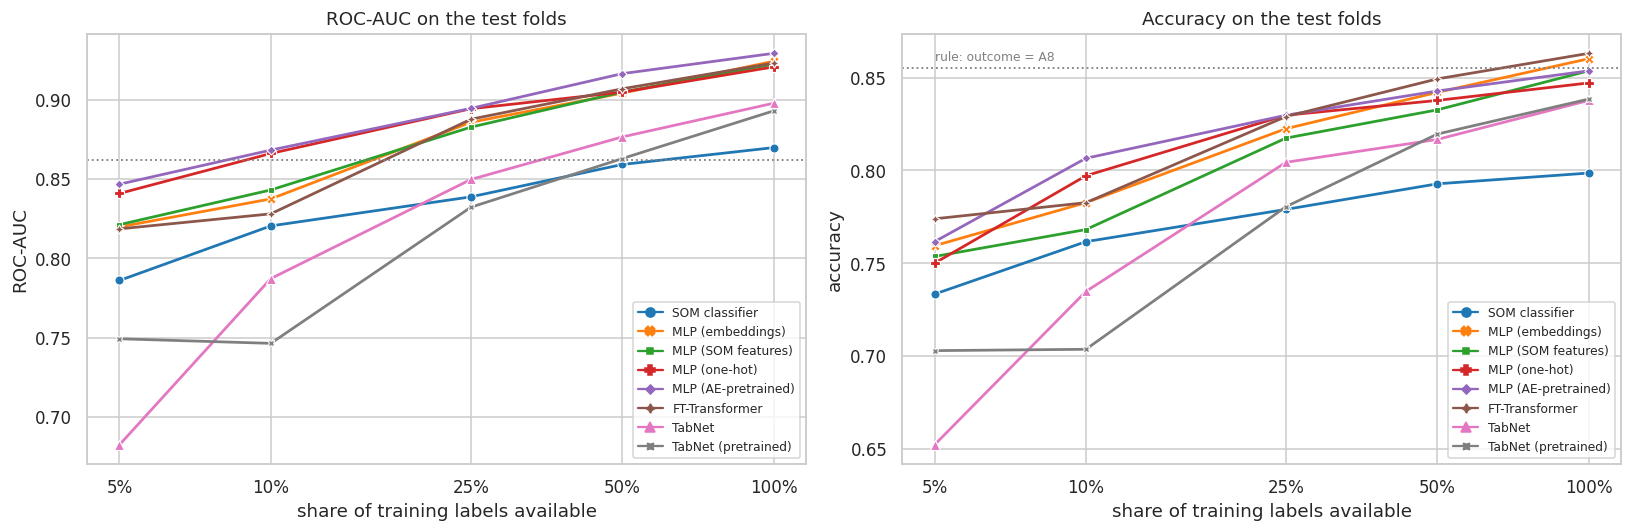

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = dict(zip(MODEL_ORDER_B, sns.color_palette("tab10", len(MODEL_ORDER_B))))
for ax, metric, title in zip(axes, ["roc_auc", "accuracy"], ["ROC-AUC on the test folds", "Accuracy on the test folds"]):
    sns.lineplot(data=semi_results, x="label_fraction", y=metric, hue="model", style="model", markers=True,
                 dashes=False, errorbar=None, hue_order=MODEL_ORDER_B, style_order=MODEL_ORDER_B,
                 palette=palette, ax=ax, linewidth=1.8)
    ax.set_xscale("log")
    ax.set_xticks(FRACTIONS)
    ax.set_xticklabels([f"{int(round(f * 100))}%" for f in FRACTIONS])
    ax.minorticks_off()
    ax.set_xlabel("share of training labels available")
    ax.set_ylabel(METRIC_LABELS[metric])
    ax.set_title(title)
    ax.legend(title="", fontsize=8, loc="lower right")
axes[0].axhline(A8_RULE["roc_auc"], color="grey", linestyle=":", linewidth=1.2)
axes[1].axhline(A8_RULE["accuracy"], color="grey", linestyle=":", linewidth=1.2)
axes[1].text(FRACTIONS[0], A8_RULE["accuracy"] + 0.004, "rule: outcome = A8", color="grey", fontsize=8)
fig.tight_layout()
save_fig(fig, "12_label_efficiency_curves.png")
plt.show()

**Observations.**

- **Overall level.** With all labels, the MLP variants and the FT-Transformer reach a ROC-AUC of 0.92 to 0.93 and an accuracy of about 0.85 to 0.86. With 5% of the labels (28 applications), their ROC-AUC is 0.82 to 0.85.
- **Reference rule.** The fixed rule "outcome = A8" reaches a ROC-AUC of 0.862 and an accuracy of 0.855 without any labels. The MLP on one-hot input (0.866) and the autoencoder-pretrained MLP (0.868) pass its ROC-AUC with 10% of the labels (55 applications). The other MLPs and the FT-Transformer need 25%, and TabNet 50%. In accuracy, the best models reach the level of the rule only when most or all labels are available. The learned models therefore rank applications considerably better than the single attribute, but they do not make better hard decisions at a threshold of 0.5.
- **SOM classifier.** It trails the MLPs and the FT-Transformer at every label fraction (0.786 at 5% labels, 0.870 at 100%) and reaches the ROC-AUC of the rule only with all labels. Its neuron vote can only separate what the regions of the map separate. In return, it trains in seconds without gradients, and every prediction can be traced to a neuron on the map.
- **FT-Transformer.** It is not better than the MLP with embeddings (ROC-AUC 0.819 to 0.923 against 0.820 to 0.924), at a higher computational cost.
- **TabNet.** It is the weakest and most variable model when labels are scarce (0.682 ± 0.126 at 5% labels) and improves to 0.898 with all labels, consistent with a model that needs more data than this dataset offers.

<a class="anchor" id="secB6"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">B6 · Effect of unsupervised structure</p>


Each pair below differs only in the unsupervised stage, and both models are evaluated on the same test folds. The gain is the paired difference in ROC-AUC (with unsupervised structure minus without). The standard error is computed over the splits and is indicative only, because the cross-validation splits share data.

,comparison,label_fraction,mean_gain,std_error,share_of_splits_improved
0,SOM features added to the MLP,0.05,0.001,0.003,0.5
1,SOM features added to the MLP,0.10,0.006,0.006,0.7
2,SOM features added to the MLP,0.25,-0.003,0.005,0.6
3,SOM features added to the MLP,0.50,0.001,0.005,0.5
4,SOM features added to the MLP,1.00,-0.002,0.003,0.3
5,Autoencoder pretraining,0.05,0.006,0.007,0.6
6,Autoencoder pretraining,0.10,0.002,0.008,0.5
7,Autoencoder pretraining,0.25,0.000,0.006,0.5
8,Autoencoder pretraining,0.50,0.012,0.006,0.8
9,Autoencoder pretraining,1.00,0.009,0.007,0.7


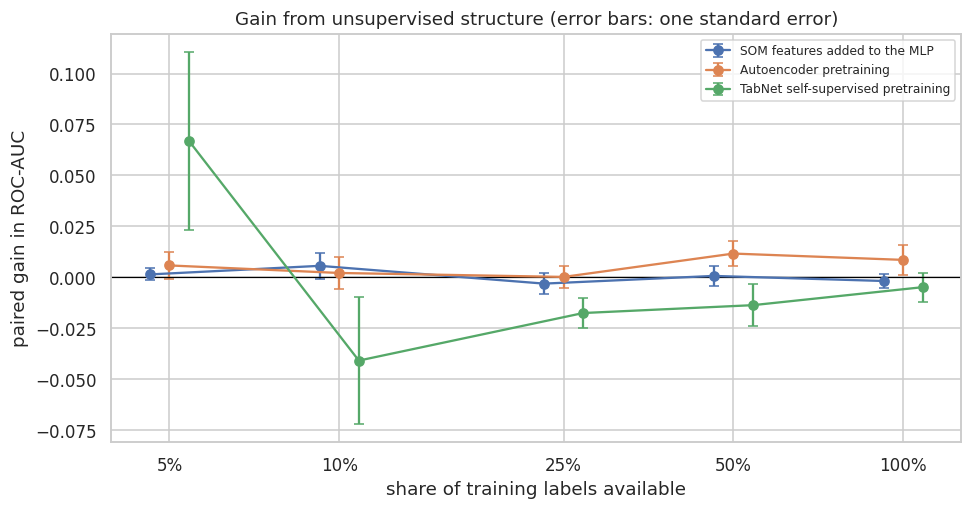

In [33]:
PAIRS = [("MLP (SOM features)", "MLP (embeddings)", "SOM features added to the MLP"),
         ("MLP (AE-pretrained)", "MLP (one-hot)", "Autoencoder pretraining"),
         ("TabNet (pretrained)", "TabNet", "TabNet self-supervised pretraining")]

wide = semi_results.pivot_table(index=["split", "label_fraction"], columns="model", values="roc_auc")
gain_rows = []
for with_structure, baseline, label in PAIRS:
    if with_structure not in wide or baseline not in wide:
        continue
    delta = (wide[with_structure] - wide[baseline]).dropna().rename("gain").reset_index()
    for fraction, group in delta.groupby("label_fraction"):
        gain_rows.append({"comparison": label, "label_fraction": fraction, "mean_gain": group["gain"].mean(),
                          "std_error": group["gain"].std() / np.sqrt(len(group)),
                          "share_of_splits_improved": (group["gain"] > 0).mean()})
gains = pd.DataFrame(gain_rows)
gains.to_csv(store.path("semi_supervised_gains.csv"), index=False)
display(gains.round(3))

fig, ax = plt.subplots(figsize=(9, 4.8))
for offset, (label, group) in zip(np.linspace(-0.04, 0.04, max(1, gains["comparison"].nunique())), gains.groupby("comparison", sort=False)):
    ax.errorbar(group["label_fraction"] * np.exp(offset * 2), group["mean_gain"], yerr=group["std_error"],
                marker="o", capsize=3, label=label)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xticks(FRACTIONS)
ax.set_xticklabels([f"{int(round(f * 100))}%" for f in FRACTIONS])
ax.minorticks_off()
ax.set_xlabel("share of training labels available")
ax.set_ylabel("paired gain in ROC-AUC")
ax.set_title("Gain from unsupervised structure (error bars: one standard error)")
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "13_unsupervised_gain.png")
plt.show()

**Observations.**

- **SOM features** add nothing. The paired gain lies between -0.003 and +0.006 ROC-AUC at every label fraction, with standard errors of 0.003 to 0.006. A plausible reason is that the MLP already receives the attributes that dominate the organisation of the SOM (`A8`, `A9` and `A10`, see A7), so the position on the map carries little new information.
- **Autoencoder pretraining** gives small gains between 0.000 and +0.012 ROC-AUC. The largest are at 50% of the labels (+0.012 ± 0.006, 80% of the splits improved) and at 100% (+0.009 ± 0.007). Most gains are within one to two standard errors, and the gain is not largest where labels are scarcest, which is where pretraining is expected to matter most. The pretrained MLP is nevertheless the best model by ROC-AUC at every label fraction, by margins comparable to the variation between splits.
- **TabNet pretraining** is inconsistent: +0.067 at 5% of the labels (± 0.044), but -0.041 at 10% (± 0.031) and -0.018 at 25% (± 0.007), and close to zero or negative from there on. The self-supervised stage does not reliably improve TabNet here.
- **Overall**, the unsupervised structure learned from all applications gives no clear benefit for predicting the outcome on this dataset. A plausible explanation is that a single attribute (`A8`) already carries most of the signal, and even 28 labeled applications give a ROC-AUC of 0.82 to 0.85, which leaves little for the unlabeled data to add. This should not be generalised to problems where the signal is spread over many attributes.

<a class="anchor" id="secB7"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">B7 · Summary of Section B and saved artifacts</p>

In [34]:
best_per_fraction = (summary_b.sort_values("roc_auc", ascending=False).groupby("label_fraction").head(1)
                     .sort_values("label_fraction")[["label_fraction", "model", "roc_auc", "accuracy"]].round(3))
best_per_fraction["label_fraction"] = (best_per_fraction["label_fraction"] * 100).round().astype(int).astype(str) + "%"
display(best_per_fraction.reset_index(drop=True))

summary_section_b = {"label_fractions": FRACTIONS, "models": MODEL_ORDER_B, "splits": int(semi_results["split"].nunique()),
                     "reference_rule_A8": A8_RULE,
                     "mean_roc_auc": {m: {str(f): round(float(v), 4) for f, v in g.set_index("label_fraction")["roc_auc"].items()}
                                      for m, g in summary_b.groupby("model")}}
store.path("summary_section_b.json").write_text(json.dumps(summary_section_b, indent=2, default=float))

artifacts = pd.DataFrame([{"file": str(p.relative_to(ARTIFACT_DIR)), "size (KB)": round(p.stat().st_size / 1024, 1)}
                          for p in sorted(ARTIFACT_DIR.rglob("*")) if p.is_file()])
display(artifacts)

,label_fraction,model,roc_auc,accuracy
0,5%,MLP (AE-pretrained),0.847,0.762
1,10%,MLP (AE-pretrained),0.868,0.807
2,25%,MLP (AE-pretrained),0.894,0.830
3,50%,MLP (AE-pretrained),0.916,0.843
4,100%,MLP (AE-pretrained),0.929,0.854


,file,size (KB)
0,anomaly_scores.csv,41.0
1,benchmark_results.csv,8.0
2,external_check.csv,0.2
3,figures/01_numeric_distributions.png,109.7
4,figures/02_discrete_distributions.png,93.3
5,figures/03_attribute_correlation.png,168.1
6,figures/04_som_hyperparameter_search.png,103.4
7,figures/05_som_overview_maps.png,51.6
8,figures/06_component_planes.png,160.7
9,figures/07_anomaly_scores_and_profile.png,77.1


<a class="anchor" id="secConclusions"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:170%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Conclusions</p>


**Fraud screening with a SOM.** A Self-Organizing Map, implemented from scratch and validated against MiniSom, provides an interpretable screening model for credit card applications: maps and component planes describe the application space, and every flag comes with the attributes that drive it. As a detector it is competitive with the neural alternatives. It matches the best detector on extreme values (ROC-AUC 0.984), is in the same range on inconsistent attribute combinations (0.636 against 0.606 to 0.665), and its result hardly depends on the grid size. The weak point is stability: about half of the flagged applications change between random seeds, so scores should be averaged over several seeds for any practical use.

**Comparison of detectors.** The VAE is the most stable detector and, together with the SOM, the best on extreme values. The autoencoder and Deep SVDD are less stable, and Deep SVDD in particular should not be used with a single seed. No detector is clearly superior: the mean ROC-AUC on the injected anomalies lies between 0.79 and 0.81 for all four.

**Semi-supervised learning.** Small MLPs are the most label-efficient models in this study. With 55 labeled applications (10%), they match the ranking quality of the single-attribute rule `A8`, and with all labels they reach a ROC-AUC of about 0.92 to 0.93. FT-Transformer and TabNet do not improve on them, and TabNet is clearly worse when labels are scarce. Unsupervised structure from the SOM, from autoencoder pretraining or from TabNet pretraining gives at most small gains, because a single attribute carries most of the signal on this dataset.

### Limitations

- The dataset has no fraud labels. Section A relies on synthetic anomalies as a proxy, and Section B predicts a credit decision, which is not fraud.
- With 690 applications and 14 anonymised attributes, differences between models are often within the variation between folds. The benchmark and the cross-validation splits share data, so the reported standard errors are indicative.
- Hyperparameters of the neural models are fixed in advance and untuned, by design. The radius and learning rate of the SOM were selected on all applications (without labels) before the benchmark, which can favour the SOM slightly over the detectors with fixed settings.
- The reference rule on `A8` was chosen after inspecting the full data and is an optimistic baseline.

### Possible extensions

- An evaluation of the screening approach on a dataset with confirmed fraud labels, for example a card transaction dataset.
- An ensemble of SOMs trained with different seeds as the screening score, with the gain in stability measured.
- An explanation layer for the neural detectors, which would allow a like-for-like comparison with the per-attribute drivers of the SOM.

### Data source and reproducibility

The data follows the structure of the Statlog (Australian Credit Approval) dataset from the UCI Machine Learning Repository. All results use fixed random seeds, and the notebook saves its trained models and tables so that a run reproduces the reported figures without retraining.